# Previsão da volatilidade da PETR4

## 0 - Índice resumido do trabalho

| Etapa | O que foi feito / Por quê | Técnica / Resultado principal |
|---|---|---|
| **1. Problema** | Prever a volatilidade da PETR4 nos 5 pregões seguintes e avaliar se o Brent acrescenta informação. | **Regressão em série temporal**, período de 2016 a 2025, com janela histórica principal de 30 observações. |
| **2. Coleta** | Obter as séries necessárias preservando suas características originais. | PETR4 via **Yahoo Finance** e Brent Spot via **EIA/FRED**. Foram obtidos 2.491 registros de PETR4 e 2.608 registros do Brent. |
| **3. Qualidade** | Identificar problemas antes de qualquer tratamento ou modelagem. | Verificação de ausentes, duplicidades, volume zero, preços e valores extremos. Foram encontrados **10 registros da PETR4 sem negociação efetiva** e **70 valores ausentes no Brent**. |
| **4. Preparação** | Manter apenas observações economicamente válidas sem criar informações artificiais. | Remoção dos registros inválidos, **sem imputação artificial**, preservando valores extremos considerados reais. |
| **5. Atributos PETR4** | Representar o comportamento recente da ação por meio de variáveis explicativas. | Criação de **retorno logarítmico**, **amplitude**, **variação logarítmica do volume** e **volatilidade histórica de 30 pregões (HV30)**. |
| **6. Atributos Brent** | Criar variáveis externas relacionadas ao comportamento do petróleo. | Criação de **retorno logarítmico** e **volatilidade histórica de 30 observações (HV30)** do Brent. |
| **7. Alvo** | Definir exatamente o que o modelo deverá prever. | O alvo é o **desvio-padrão dos retornos dos 5 pregões seguintes da PETR4**. Foram obtidos **2.476 alvos válidos**. |
| **8. Integração temporal** | Juntar PETR4 e Brent respeitando a disponibilidade temporal das informações. | PETR4 foi usada como calendário de referência, com **defasagem conservadora do Brent** e integração temporal. Resultado: **0 uso de informação futura**. |
| **9. Base supervisionada** | Reunir atributos e alvo nas mesmas datas para permitir a modelagem. | A base final ficou com **2.446 observações válidas**. Foram removidas 30 observações iniciais pela construção da HV30 e 5 finais pela construção do alvo. |
| **10. Protocolo de avaliação** | Definir como os modelos serão avaliados respeitando a ordem temporal e evitando vazamento. | **Walk-Forward com janela expansiva**, **baseline HV30**, `StandardScaler` e proteção temporal do alvo. Configuração principal: **30 pregões passados → 5 pregões futuros**. |
| **11. Avaliação histórica** | Executar o protocolo entre 2017 e 2023. | Foram comparados **Baseline HV30**, **Regressão Linear PETR4** e **Regressão Linear PETR4 + Brent**. A regressão PETR4 reduziu o RMSE em aproximadamente **18,56%** frente ao baseline. |
| **12. Teste final** | Repetir o protocolo em um período reservado, sem alterar a metodologia. | Em **2024–2025**, foram realizadas 496 previsões com **0 violações temporais**. A regressão PETR4 apresentou RMSE aproximadamente **2,44% menor** que o baseline HV30, mas o baseline teve menor MAE e menor Bias. |
| **13. Consolidação dos resultados** | Verificar estabilidade ao longo do tempo. | Foram avaliadas **2.222 previsões**. A regressão PETR4 apresentou RMSE inferior ao baseline HV30 em **8 dos 9 anos**; **2022** foi a única exceção. |
| **14. Extração de conhecimento** | Identificar quais atributos apresentaram maior influência nas regressões. | **PETR4_Amplitude** e **PETR4_HV30** foram os atributos com associações mais fortes e estáveis. |
| **15. Comparação com a literatura** | Posicionar os resultados em relação a trabalhos anteriores de previsão de volatilidade. | Referência metodológica: **Amirshahi & Lahmiri (2023)**. A comparação foi conceitual e metodológica. |
| **16. Conclusão** | Responder à pergunta inicial do trabalho. | A regressão PETR4 apresentou vantagem pelo **RMSE**, mas essa vantagem caiu de **18,56% no histórico para 2,44% no teste final** e não ocorreu em todas as métricas. As duas representações do Brent não apresentaram melhoria consistente. |
| **17. Próximos passos** | Evoluir o estudo mantendo rigor temporal e metodológico. | Novos atributos, controles, diferentes janelas, Machine Learning, GARCH, Deep Learning e testes estatísticos de comparação. |

# Previsão da volatilidade da PETR4

## 1. Definição do problema e configuração temporal

**Objetivo:** prever a volatilidade da PETR4 nos **5 pregões seguintes** e avaliar se informações históricas do **Brent Spot** acrescentam capacidade preditiva.

**Tipo de problema:** regressão em série temporal.

**Experimentos:**
1. **PETR4**: previsão utilizando apenas informações históricas da própria ação;
2. **PETR4 + Brent**: mesma previsão acrescentando informações históricas do
   petróleo Brent Spot.

**Configuração:**
- dados diários de aproximadamente **10 anos** (2016 a 2025);
- janela histórica principal: **30 observações**;
- horizonte: **5 pregões**;
- previsão realizada após o fechamento do pregão.

De forma simplificada:

**Passado utilizado como entrada**: `t-29 ... t` 

**Previsão**: `t+1 ... t+5`


In [1]:
# =========================================================
# CONFIGURAÇÃO DO EXPERIMENTO
# =========================================================

# Período aproximado de 10 anos
DATA_INICIO = "2016-01-01"
DATA_FIM = "2025-12-31"

# Configuração temporal
FREQUENCIA = "diária"
JANELA_HISTORICA = 30       # pregões anteriores, incluindo t
HORIZONTE_PREVISAO = 5      # pregões futuros

# Problema
TIPO_PROBLEMA = "Regressão em série temporal"
ATIVO_ALVO = "PETR4"
VARIAVEL_EXTERNA = "Brent Spot"

# Nome que será utilizado posteriormente para o alvo
NOME_ALVO = "PETR4_Vol_Observada_5d"

print("CONFIGURAÇÃO DO EXPERIMENTO")
print("-" * 45)
print(f"Período:           {DATA_INICIO} a {DATA_FIM}")
print(f"Frequência:        {FREQUENCIA}")
print(f"Janela histórica:  {JANELA_HISTORICA} pregões")
print(f"Horizonte:         {HORIZONTE_PREVISAO} pregões")
print(f"Tipo do problema:  {TIPO_PROBLEMA}")
print(f"Ativo-alvo:        {ATIVO_ALVO}")
print(f"Variável externa:  {VARIAVEL_EXTERNA}")
print(f"Alvo:              {NOME_ALVO}")

CONFIGURAÇÃO DO EXPERIMENTO
---------------------------------------------
Período:           2016-01-01 a 2025-12-31
Frequência:        diária
Janela histórica:  30 pregões
Horizonte:         5 pregões
Tipo do problema:  Regressão em série temporal
Ativo-alvo:        PETR4
Variável externa:  Brent Spot
Alvo:              PETR4_Vol_Observada_5d


### Síntese da etapa

A pergunta central é simples:

> **As informações utilizadas do Brent melhoram a previsão da volatilidade da PETR4 em relação ao uso apenas da própria PETR4?**

O estudo foi estruturado para responder essa questão preservando a ordem temporal dos dados e evitando vazamento de informação.

## 2. Coleta das séries temporais

Foram coletadas duas séries diárias:

- **PETR4 (`PETR4.SA`)**: ação preferencial da Petrobras, com preços ajustados em **Reais** e volume obtidos pelo Yahoo Finance;
- **Brent Spot (`DCOILBRENTEU`)**: preço spot diário do petróleo Brent,
  disponibilizado pela EIA por meio do FRED, em **US$/barril**.

**As séries foram mantidas separadas nesta etapa porque possuem calendários diferentes.**

In [2]:
import warnings
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# =========================================================
# CONFIGURAÇÃO DO EXPERIMENTO
# =========================================================

DATA_INICIO = "2016-01-01"
DATA_FIM = "2025-12-31"

# O parâmetro end do yfinance é exclusivo.
DATA_FIM_YF = (
    pd.Timestamp(DATA_FIM) + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

warnings.filterwarnings(
    "ignore",
    message=".*Timestamp.utcnow is deprecated.*",
    category=Warning
)

# =========================================================
# PETR4 - YAHOO FINANCE
# =========================================================

petr4 = yf.download(
    "PETR4.SA",
    start=DATA_INICIO,
    end=DATA_FIM_YF,
    auto_adjust=True,
    progress=False
)

# Algumas versões do yfinance retornam MultiIndex
if isinstance(petr4.columns, pd.MultiIndex):
    petr4.columns = petr4.columns.get_level_values(0)

colunas_petr4 = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

petr4 = petr4[colunas_petr4].copy()

petr4.columns = [
    "PETR4_Open",
    "PETR4_High",
    "PETR4_Low",
    "PETR4_Close",
    "PETR4_Volume"
]

petr4.index = pd.to_datetime(petr4.index)
petr4.index.name = "Date"
petr4 = petr4.sort_index()
#petr4.to_csv("petr4_2016_2025.csv")

# =========================================================
# BRENT SPOT - FRED / EIA
# =========================================================

url_brent = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    f"?id=DCOILBRENTEU"
    f"&cosd={DATA_INICIO}"
    f"&coed={DATA_FIM}"
)

brent = pd.read_csv(
    url_brent,
    na_values="."
)

# A primeira coluna do arquivo corresponde à data
coluna_data = brent.columns[0]

brent = brent.rename(
    columns={
        coluna_data: "Date",
        "DCOILBRENTEU": "BRENT_Spot"
    }
)

brent["Date"] = pd.to_datetime(brent["Date"])

brent["BRENT_Spot"] = pd.to_numeric(
    brent["BRENT_Spot"],
    errors="coerce"
)

brent = brent.set_index("Date")
brent = brent.sort_index()
#brent.to_csv("brent_spot_2016_2025.csv")

# =========================================================
# RESUMO INICIAL
# =========================================================

# print("VERSÕES")
# print("-" * 45)
# print(f"pandas:   {pd.__version__}")
# print(f"yfinance: {yf.__version__}")

print("\nPETR4")
print("-" * 45)
print(
    f"Período disponível: "
    f"{petr4.index.min().date()} a {petr4.index.max().date()}"
)
print(f"Quantidade de registros: {len(petr4)}")
display(petr4.head())

print("\nBRENT SPOT")
print("-" * 45)
print(
    f"Período disponível: "
    f"{brent.index.min().date()} a {brent.index.max().date()}"
)
print(f"Quantidade de registros: {len(brent)}")
display(brent.head())


PETR4
---------------------------------------------
Período disponível: 2016-01-04 a 2025-12-30
Quantidade de registros: 2491


,PETR4_Open,PETR4_High,PETR4_Low,PETR4_Close,PETR4_Volume
Date,,,,,
2016-01-04,1.645857,1.761093,1.640847,1.721011,45962100
2016-01-05,1.733537,1.753577,1.658383,1.673414,29446700
2016-01-06,1.635837,1.638342,1.603270,1.603270,67507200
2016-01-07,1.550663,1.610786,1.523107,1.568199,57387900
2016-01-08,1.598260,1.615796,1.535633,1.570704,52100300



BRENT SPOT
---------------------------------------------
Período disponível: 2016-01-04 a 2025-12-31
Quantidade de registros: 2608


,BRENT_Spot
Date,
2016-01-04,36.28
2016-01-05,35.56
2016-01-06,33.89
2016-01-07,33.57
2016-01-08,31.67


### Síntese da etapa

- PETR4: **2.491 registros**;
- Brent: **2.608 registros**;
- período aproximado: **2016–2025**.

## 3. Entendimento e qualidade dos dados

Antes da modelagem foram verificados:

- valores ausentes;
- duplicidades;
- ordenação temporal;
- preços inválidos;
- volume zero;
- consistência entre máxima, mínima, abertura e fechamento.

Movimentos extremos reais (possíveis outliers) foram preservados.

In [3]:
# =========================================================
# QUALIDADE DOS DADOS - PETR4
# =========================================================

print("PETR4")
print("=" * 60)

print("\nTipos dos atributos:")
display(petr4.dtypes)

print("\nOrdenação temporal:")
print("Índice crescente:", petr4.index.is_monotonic_increasing)

print("\nDatas duplicadas:")
print(petr4.index.duplicated().sum())

print("\nValores ausentes:")
display(petr4.isna().sum())

print("\nValores menores ou iguais a zero:")
colunas_preco = [
    "PETR4_Open",
    "PETR4_High",
    "PETR4_Low",
    "PETR4_Close"
]

for coluna in colunas_preco:
    print(f"{coluna}: {(petr4[coluna] <= 0).sum()}")

print(f"PETR4_Volume negativo: {(petr4['PETR4_Volume'] < 0).sum()}")
print(f"PETR4_Volume igual a zero: {(petr4['PETR4_Volume'] == 0).sum()}")

# Consistência OHLC
inconsistencia_high = (
    (petr4["PETR4_High"] < petr4["PETR4_Open"]) |
    (petr4["PETR4_High"] < petr4["PETR4_Close"]) |
    (petr4["PETR4_High"] < petr4["PETR4_Low"])
)

inconsistencia_low = (
    (petr4["PETR4_Low"] > petr4["PETR4_Open"]) |
    (petr4["PETR4_Low"] > petr4["PETR4_Close"]) |
    (petr4["PETR4_Low"] > petr4["PETR4_High"])
)

print("\nInconsistências OHLC:")
print("High inconsistente:", inconsistencia_high.sum())
print("Low inconsistente: ", inconsistencia_low.sum())

print("\nEstatísticas descritivas:")
display(petr4.describe())


# =========================================================
# QUALIDADE DOS DADOS - BRENT
# =========================================================

print("\n\nBRENT SPOT")
print("=" * 60)

print("\nTipos dos atributos:")
display(brent.dtypes)

print("\nOrdenação temporal:")
print("Índice crescente:", brent.index.is_monotonic_increasing)

print("\nDatas duplicadas:")
print(brent.index.duplicated().sum())

print("\nValores ausentes:")
display(brent.isna().sum())

print("\nValores menores ou iguais a zero:")
print((brent["BRENT_Spot"] <= 0).sum())

print("\nEstatísticas descritivas:")
display(brent.describe())

PETR4

Tipos dos atributos:


PETR4_Open      float64
PETR4_High      float64
PETR4_Low       float64
PETR4_Close     float64
PETR4_Volume      int64
dtype: object


Ordenação temporal:
Índice crescente: True

Datas duplicadas:
0

Valores ausentes:


PETR4_Open      0
PETR4_High      0
PETR4_Low       0
PETR4_Close     0
PETR4_Volume    0
dtype: int64


Valores menores ou iguais a zero:
PETR4_Open: 0
PETR4_High: 0
PETR4_Low: 0
PETR4_Close: 0
PETR4_Volume negativo: 0
PETR4_Volume igual a zero: 10

Inconsistências OHLC:
High inconsistente: 22
Low inconsistente:  20

Estatísticas descritivas:


...

BRENT_Spot    float64
dtype: object


Ordenação temporal:
Índice crescente: True

Datas duplicadas:
0

Valores ausentes:


BRENT_Spot    70
dtype: int64


Valores menores ou iguais a zero:
0

Estatísticas descritivas:


,BRENT_Spot
count,2538.000000
mean,67.847561
std,18.896041
min,9.120000
25%,54.692500
50%,68.390000
75%,79.387500
max,133.180000


### Síntese da etapa

**PETR4:** sem valores ausentes ou duplicidades, mas com **10 registros de volume zero**.

**Brent:** **70 observações sem cotação**, associadas principalmente a diferenças de calendário.

Pequenas inconsistências de máxima/mínima foram identificadas como precisão numérica, e não erros econômicos.

### 3.1 Investigação das ocorrências

As ocorrências identificadas foram analisadas antes de qualquer exclusão.

Objetivo: evitar tratar automaticamente como erro aquilo que pode representar uma característica real das séries financeiras.

In [4]:
# =========================================================
# PETR4 - VOLUMES IGUAIS A ZERO
# =========================================================

print("PETR4 - VOLUME IGUAL A ZERO")
print("=" * 60)

volume_zero = petr4[petr4["PETR4_Volume"] == 0]

print(f"Quantidade: {len(volume_zero)}")
display(volume_zero)


# =========================================================
# PETR4 - INVESTIGAÇÃO DAS INCONSISTÊNCIAS OHLC
# =========================================================

print("\nPETR4 - POSSÍVEIS INCONSISTÊNCIAS OHLC")
print("=" * 60)

problemas_ohlc = petr4[inconsistencia_high | inconsistencia_low].copy()

# Mede o quanto High ficou abaixo de Open/Close
problemas_ohlc["Dif_High_Open"] = (
    problemas_ohlc["PETR4_High"] - problemas_ohlc["PETR4_Open"]
)

problemas_ohlc["Dif_High_Close"] = (
    problemas_ohlc["PETR4_High"] - problemas_ohlc["PETR4_Close"]
)

# Mede o quanto Low ficou acima de Open/Close
problemas_ohlc["Dif_Low_Open"] = (
    problemas_ohlc["PETR4_Low"] - problemas_ohlc["PETR4_Open"]
)

problemas_ohlc["Dif_Low_Close"] = (
    problemas_ohlc["PETR4_Low"] - problemas_ohlc["PETR4_Close"]
)

print(f"Quantidade de datas envolvidas: {len(problemas_ohlc)}")

display(
    problemas_ohlc[
        [
            "PETR4_Open",
            "PETR4_High",
            "PETR4_Low",
            "PETR4_Close",
            "Dif_High_Open",
            "Dif_High_Close",
            "Dif_Low_Open",
            "Dif_Low_Close"
        ]
    ]
)


# =========================================================
# BRENT - VALORES AUSENTES
# =========================================================

print("\nBRENT SPOT - VALORES AUSENTES")
print("=" * 60)

brent_ausentes = brent[brent["BRENT_Spot"].isna()]

print(f"Quantidade: {len(brent_ausentes)}")
display(brent_ausentes)

PETR4 - VOLUME IGUAL A ZERO
Quantidade: 10


,PETR4_Open,PETR4_High,PETR4_Low,PETR4_Close,PETR4_Volume
Date,,,,,
2017-05-29,3.426991,3.426991,3.426991,3.426991,0
2017-06-15,3.161450,3.161450,3.161450,3.161450,0
2017-09-07,3.762676,3.762676,3.762676,3.762676,0
2017-10-12,4.028218,4.028218,4.028218,4.028218,0
2017-11-02,4.233636,4.233636,4.233636,4.233636,0
2017-11-15,3.845345,3.845345,3.845345,3.845345,0
2017-11-20,4.013187,4.013187,4.013187,4.013187,0
2017-12-25,3.945549,3.945549,3.945549,3.945549,0
2017-12-29,4.033229,4.033229,4.033229,4.033229,0



PETR4 - POSSÍVEIS INCONSISTÊNCIAS OHLC
Quantidade de datas envolvidas: 42


,PETR4_Open,PETR4_High,PETR4_Low,PETR4_Close,Dif_High_Open,Dif_High_Close,Dif_Low_Open,Dif_Low_Close
Date,,,,,,,,
2016-03-02,1.305162,1.415387,1.290132,1.415387,0.110225,-2.220446e-16,-0.015031,-1.252555e-01
2016-03-14,2.036655,2.054190,1.853781,1.853781,0.017536,2.004087e-01,-0.182873,2.220446e-16
2016-04-05,1.953986,1.953986,1.953986,1.953986,0.000000,-2.220446e-16,0.000000,-2.220446e-16
2016-04-06,1.898874,1.898874,1.898874,1.898874,0.000000,-2.220446e-16,0.000000,-2.220446e-16
2016-04-13,2.377350,2.377350,2.377350,2.377350,0.000000,-4.440892e-16,0.000000,-4.440892e-16
2016-05-12,2.605315,2.622851,2.452503,2.452503,0.017536,1.703476e-01,-0.152812,4.440892e-16
2016-09-06,3.429496,3.502144,3.389414,3.502144,0.072648,-4.440892e-16,-0.040082,-1.127299e-01
2016-10-03,3.424486,3.499639,3.411960,3.499639,0.075153,-4.440892e-16,-0.012526,-8.767896e-02
2016-12-16,3.732614,3.792737,3.697543,3.697543,0.060123,9.519422e-02,-0.035071,4.440892e-16



BRENT SPOT - VALORES AUSENTES
Quantidade: 70


,BRENT_Spot
Date,
2016-02-15,NaN
2016-03-25,NaN
2016-05-30,NaN
2016-12-26,NaN
2016-12-27,NaN
...,...
2025-05-05,NaN
2025-05-26,NaN
2025-08-25,NaN


### Síntese da investigação

- Os **10 registros de volume zero** da PETR4 representam ausência de negociação efetiva.
- As diferenças mínimas entre preços eram apenas efeitos de ponto flutuante.
- Os valores ausentes do Brent não foram preenchidos artificialmente.
- Movimentos extremos do Brent em 2020 foram mantidos por representarem choques reais de mercado.

## 4. Preparação das séries

Foram aplicados apenas tratamentos justificados:

- remoção dos registros da PETR4 sem negociação efetiva;
- remoção das observações do Brent sem cotação;
- manutenção dos demais registros, inclusive extremos reais;
- nenhuma imputação artificial de preços.

In [5]:
# =========================================================
# PREPARAÇÃO DA PETR4
# =========================================================

petr4_original = petr4.copy()

# Remove registros sem negociação efetiva
petr4_limpa = petr4[
    petr4["PETR4_Volume"] > 0
].copy()

print("PETR4")
print("-" * 50)

print(
    f"Registros antes:  "
    f"{len(petr4_original)}"
)

print(
    f"Registros depois: "
    f"{len(petr4_limpa)}"
)

print(
    f"Removidos:        "
    f"{len(petr4_original) - len(petr4_limpa)}"
)


# =========================================================
# PREPARAÇÃO DO BRENT
# =========================================================

brent_original = brent.copy()

# Mantém somente observações com preço disponível
brent_limpo = (
    brent
    .dropna(
        subset=["BRENT_Spot"]
    )
    .copy()
)

print("\nBRENT SPOT")
print("-" * 50)

print(
    f"Registros antes:  "
    f"{len(brent_original)}"
)

print(
    f"Registros depois: "
    f"{len(brent_limpo)}"
)

print(
    f"Removidos:        "
    f"{len(brent_original) - len(brent_limpo)}"
)


# =========================================================
# VERIFICAÇÃO FINAL
# =========================================================

print("\nVERIFICAÇÃO")
print("-" * 50)

print("PETR4 - valores ausentes:")
print(
    petr4_limpa
    .isna()
    .sum()
    .sum()
)

print("\nBrent - valores ausentes:")
print(
    brent_limpo
    .isna()
    .sum()
    .sum()
)

print(
    "\nPETR4 - índice crescente:",
    petr4_limpa.index.is_monotonic_increasing
)

print(
    "Brent - índice crescente:",
    brent_limpo.index.is_monotonic_increasing
)

PETR4


--------------------------------------------------
Registros antes:  2491
Registros depois: 2481
Removidos:        10

BRENT SPOT
--------------------------------------------------
Registros antes:  2608
Registros depois: 2538
Removidos:        70

VERIFICAÇÃO
--------------------------------------------------
PETR4 - valores ausentes:
0

Brent - valores ausentes:
0

PETR4 - índice crescente: True
Brent - índice crescente: True


### Síntese da etapa

Após a preparação:

- PETR4: **2.481 registros válidos**;
- Brent: **2.538 registros válidos**.

As janelas posteriores passam a representar observações efetivamente disponíveis em cada mercado.

## 5. Atributos temporais da PETR4

Foram construídos quatro atributos principais:

- `PETR4_Retorno` — retorno diário logarítmico;
- `PETR4_Amplitude` — relação diária entre máxima e mínima;
- `PETR4_Var_Volume` — variação logarítmica do volume negociado
  entre dois pregões consecutivos;
- `PETR4_HV30` — desvio padrão / volatilidade histórica dos retornos
  logarítmicos observados nos últimos 30 pregões - Essa será a definição de volatilidade histórica para fins deste trabalho.

Colunas percentuais adicionais foram mantidas apenas para facilitar a interpretação.

In [6]:
import numpy as np

# =========================================================
# ATRIBUTOS TEMPORAIS DA PETR4
# =========================================================

petr4_feat = petr4_limpa.copy()

# ---------------------------------------------------------
# Retorno logarítmico diário
# ---------------------------------------------------------

petr4_feat["PETR4_Retorno"] = np.log(
    petr4_feat["PETR4_Close"] /
    petr4_feat["PETR4_Close"].shift(1)
)

# Retorno percentual diário
# Usado apenas para interpretação e comparação didática
petr4_feat["PETR4_Retorno_Pct"] = (
    petr4_feat["PETR4_Close"].pct_change() * 100
)

# ---------------------------------------------------------
# Amplitude relativa diária
# ---------------------------------------------------------

petr4_feat["PETR4_Amplitude"] = np.log(
    petr4_feat["PETR4_High"] /
    petr4_feat["PETR4_Low"]
)

# ---------------------------------------------------------
# Variação do volume
# ---------------------------------------------------------

# Variação logarítmica do volume
petr4_feat["PETR4_Var_Volume"] = np.log(
    petr4_feat["PETR4_Volume"] /
    petr4_feat["PETR4_Volume"].shift(1)
)

# Variação percentual do volume
# Usada apenas para interpretação e comparação didática
petr4_feat["PETR4_Var_Volume_Pct"] = (
    petr4_feat["PETR4_Volume"].pct_change() * 100
)

# ---------------------------------------------------------
# Volatilidade histórica de 30 pregões
# ---------------------------------------------------------

petr4_feat["PETR4_HV30"] = (
    petr4_feat["PETR4_Retorno"]
    .rolling(window=JANELA_HISTORICA)
    .std(ddof=0)
)

# Volatilidade histórica em percentual
# Usada apenas para interpretação didática
petr4_feat["PETR4_HV30_Pct"] = (
    petr4_feat["PETR4_HV30"] * 100
)

# =========================================================
# VERIFICAÇÃO
# =========================================================

print("PETR4 - ATRIBUTOS TEMPORAIS")
print("=" * 70)

print(f"Quantidade de registros: {len(petr4_feat)}")

# ---------------------------------------------------------
# Valores ausentes
# ---------------------------------------------------------

print("\nValores ausentes por atributo:")

print(
    petr4_feat[
        [
            "PETR4_Retorno",
            "PETR4_Retorno_Pct",
            "PETR4_Amplitude",
            "PETR4_Var_Volume",
            "PETR4_Var_Volume_Pct",
            "PETR4_HV30",
            "PETR4_HV30_Pct"
        ]
    ].isna().sum()
)

# ---------------------------------------------------------
# Primeiras observações
# ---------------------------------------------------------

print("\nPrimeiras observações:")

display(
    petr4_feat[
        [
            "PETR4_Close",
            "PETR4_Volume",
            "PETR4_Retorno",
            "PETR4_Retorno_Pct",
            "PETR4_Var_Volume",
            "PETR4_Var_Volume_Pct",
            "PETR4_Amplitude",
            "PETR4_HV30",
            "PETR4_HV30_Pct"
        ]
    ].head(35)
)

# ---------------------------------------------------------
# Estatísticas descritivas
# ---------------------------------------------------------

print("\nEstatísticas descritivas dos atributos:")

display(
    petr4_feat[
        [
            "PETR4_Retorno",
            "PETR4_Retorno_Pct",
            "PETR4_Amplitude",
            "PETR4_Var_Volume",
            "PETR4_Var_Volume_Pct",
            "PETR4_HV30",
            "PETR4_HV30_Pct"
        ]
    ].describe()
)

PETR4 - ATRIBUTOS TEMPORAIS
Quantidade de registros: 2481

Valores ausentes por atributo:
PETR4_Retorno            1
PETR4_Retorno_Pct        1
PETR4_Amplitude          0
PETR4_Var_Volume         1
PETR4_Var_Volume_Pct     1
PETR4_HV30              30
PETR4_HV30_Pct          30
dtype: int64

Primeiras observações:


,PETR4_Close,PETR4_Volume,PETR4_Retorno,PETR4_Retorno_Pct,PETR4_Var_Volume,PETR4_Var_Volume_Pct,PETR4_Amplitude,PETR4_HV30,PETR4_HV30_Pct
Date,,,,,,,,,
2016-01-04,1.721011,45962100,NaN,NaN,NaN,NaN,0.070722,NaN,NaN
2016-01-05,1.673414,29446700,-0.028046,-2.765631,-0.445235,-35.932649,0.055815,NaN,NaN
2016-01-06,1.603270,67507200,-0.042820,-4.191639,0.829652,129.252174,0.021639,NaN,NaN
2016-01-07,1.568199,57387900,-0.022118,-2.187490,-0.162401,-14.989957,0.055970,NaN,NaN
2016-01-08,1.570704,52100300,0.001596,0.159749,-0.096663,-9.213789,0.050885,NaN,NaN
2016-01-11,1.525612,51334000,-0.029128,-2.870813,-0.014817,-1.470817,0.040491,NaN,NaN
2016-01-12,1.385326,81627800,-0.096460,-9.195396,0.463817,59.013130,0.104997,NaN,NaN
2016-01-13,1.320193,70874300,-0.048158,-4.701635,-0.141262,-13.173821,0.089231,NaN,NaN
2016-01-14,1.425408,76854200,0.076680,7.969645,0.081002,8.437332,0.103605,NaN,NaN



Estatísticas descritivas dos atributos:


,PETR4_Retorno,PETR4_Retorno_Pct,PETR4_Amplitude,PETR4_Var_Volume,PETR4_Var_Volume_Pct,PETR4_HV30,PETR4_HV30_Pct
count,2480.000000,2480.000000,2481.000000,2480.000000,2480.000000,2451.000000,2451.000000
mean,0.001139,0.153188,0.030117,-0.000404,29.502576,0.024010,2.400984
std,0.028179,2.777843,0.019991,0.485821,627.389833,0.013433,1.343350
min,-0.352367,-29.697767,0.000000,-5.480111,-99.583113,0.008240,0.823996
25%,-0.010941,-1.088111,0.017899,-0.260752,-22.952765,0.016530,1.652968
50%,0.001382,0.138274,0.025280,-0.016992,-1.684858,0.021425,2.142528
75%,0.014253,1.435552,0.036641,0.249820,28.379493,0.026320,2.631978
max,0.200671,22.222205,0.281792,5.560684,25900.061576,0.108515,10.851481


### Síntese da etapa

Os atributos representam diferentes aspectos do comportamento recente da ação:

- direção do retorno;
- oscilação intradiária;
- mudança no volume;
- persistência da volatilidade.

A `HV30` média ficou próxima de **2,4%**.

Uso logaritmico: 

Por exemplo, um aumento de volume de 45 milhões para 90 milhões representa:

- variação absoluta de +45 milhões;
- variação percentual de +100%;
- variação logarítmica de aproximadamente 0,693.

As medidas percentual e logarítmica carregam informações muito semelhantes
sobre a variação relativa, mas a transformação logarítmica apresenta
propriedades matemáticas convenientes para séries temporais financeiras,
como simetria entre movimentos inversos e aditividade ao longo do tempo.

## 6. Atributos temporais do Brent

Para o Brent foram utilizados:

- `BRENT_Retorno` — retorno logarítmico diário;
- `BRENT_HV30` — volatilidade histórica de 30 observações.

Também foram mantidas versões percentuais apenas para interpretação.

In [7]:
# =========================================================
# ATRIBUTOS TEMPORAIS DO BRENT SPOT
# =========================================================

brent_feat = brent_limpo.copy()

# ---------------------------------------------------------
# Retorno logarítmico diário
# ---------------------------------------------------------

brent_feat["BRENT_Retorno"] = np.log(
    brent_feat["BRENT_Spot"] /
    brent_feat["BRENT_Spot"].shift(1)
)

# Retorno percentual diário
# Usado apenas para interpretação e comparação didática
brent_feat["BRENT_Retorno_Pct"] = (
    brent_feat["BRENT_Spot"].pct_change() * 100
)

# ---------------------------------------------------------
# Volatilidade histórica de 30 observações
# ---------------------------------------------------------

brent_feat["BRENT_HV30"] = (
    brent_feat["BRENT_Retorno"]
    .rolling(window=JANELA_HISTORICA)
    .std(ddof=0)
)

# Volatilidade histórica em percentual
# Usada apenas para interpretação didática
brent_feat["BRENT_HV30_Pct"] = (
    brent_feat["BRENT_HV30"] * 100
)

# =========================================================
# VERIFICAÇÃO
# =========================================================

print("BRENT SPOT - ATRIBUTOS TEMPORAIS")
print("=" * 70)

print(f"Quantidade de registros: {len(brent_feat)}")

# ---------------------------------------------------------
# Valores ausentes
# ---------------------------------------------------------

print("\nValores ausentes por atributo:")

print(
    brent_feat[
        [
            "BRENT_Retorno",
            "BRENT_Retorno_Pct",
            "BRENT_HV30",
            "BRENT_HV30_Pct"
        ]
    ].isna().sum()
)

# ---------------------------------------------------------
# Primeiras observações
# ---------------------------------------------------------

print("\nPrimeiras observações:")

display(
    brent_feat[
        [
            "BRENT_Spot",
            "BRENT_Retorno",
            "BRENT_Retorno_Pct",
            "BRENT_HV30",
            "BRENT_HV30_Pct"
        ]
    ].head(35)
)

# ---------------------------------------------------------
# Estatísticas descritivas
# ---------------------------------------------------------

print("\nEstatísticas descritivas dos atributos:")

display(
    brent_feat[
        [
            "BRENT_Retorno",
            "BRENT_Retorno_Pct",
            "BRENT_HV30",
            "BRENT_HV30_Pct"
        ]
    ].describe()
)

# =========================================================
# VERIFICAÇÃO DOS MAIORES MOVIMENTOS DO BRENT
# =========================================================

print("\nMaiores movimentos do Brent:")

extremos_brent = (
    brent_feat
    .dropna(subset=["BRENT_Retorno"])
    .assign(
        Retorno_Absoluto=lambda x: x["BRENT_Retorno"].abs()
    )
    .sort_values(
        "Retorno_Absoluto",
        ascending=False
    )
    .head(10)
)

display(
    extremos_brent[
        [
            "BRENT_Spot",
            "BRENT_Retorno",
            "BRENT_Retorno_Pct",
            "BRENT_HV30",
            "BRENT_HV30_Pct"
        ]
    ]
)

BRENT SPOT - ATRIBUTOS TEMPORAIS
Quantidade de registros: 2538

Valores ausentes por atributo:
BRENT_Retorno         1
BRENT_Retorno_Pct     1
BRENT_HV30           30
BRENT_HV30_Pct       30
dtype: int64

Primeiras observações:


,BRENT_Spot,BRENT_Retorno,BRENT_Retorno_Pct,BRENT_HV30,BRENT_HV30_Pct
Date,,,,,
2016-01-04,36.28,NaN,NaN,NaN,NaN
2016-01-05,35.56,-0.020045,-1.984564,NaN,NaN
2016-01-06,33.89,-0.048101,-4.696288,NaN,NaN
2016-01-07,33.57,-0.009487,-0.944231,NaN,NaN
2016-01-08,31.67,-0.058263,-5.659815,NaN,NaN
2016-01-11,30.14,-0.049517,-4.831070,NaN,NaN
2016-01-12,29.14,-0.033741,-3.317850,NaN,NaN
2016-01-13,28.58,-0.019405,-1.921757,NaN,NaN
2016-01-14,28.84,0.009056,0.909727,NaN,NaN



Estatísticas descritivas dos atributos:


,BRENT_Retorno,BRENT_Retorno_Pct,BRENT_HV30,BRENT_HV30_Pct
count,2537.000000,2537.000000,2508.000000,2508.000000
mean,0.000207,0.067261,0.023259,2.325931
std,0.030861,3.022519,0.019482,1.948178
min,-0.643699,-47.465438,0.009223,0.922259
25%,-0.011605,-1.153794,0.015084,1.508379
50%,0.001234,0.123440,0.019394,1.939381
75%,0.012922,1.300552,0.025104,2.510361
max,0.412023,50.986842,0.184098,18.409845



Maiores movimentos do Brent:


,BRENT_Spot,BRENT_Retorno,BRENT_Retorno_Pct,BRENT_HV30,BRENT_HV30_Pct
Date,,,,,
2020-04-21,9.12,-0.643699,-47.465438,0.165007,16.500725
2020-04-22,13.77,0.412023,50.986842,0.180575,18.057492
2020-04-02,20.24,0.301613,35.203741,0.104347,10.434739
2020-03-31,14.85,-0.256389,-22.615946,0.084705,8.470542
2020-03-09,35.33,-0.255175,-22.521930,0.053653,5.365323
2020-05-05,25.46,0.221574,24.803922,0.184098,18.409845
2020-04-09,20.23,-0.220471,-19.785884,0.120667,12.066657
2020-03-18,22.79,-0.204811,-18.519843,0.067810,6.781043
2020-04-03,24.33,0.184049,20.207510,0.111556,11.155615


### Síntese da etapa

A maior queda diária observada foi de aproximadamente 47,5% e o maior avanço
foi de aproximadamente 51,0%. A verificação das datas mostrou que esses valores
correspondem ao período de forte instabilidade do mercado de petróleo durante
a pandemia de COVID-19 e são compatíveis com os preços históricos oficiais do
Brent.

A volatilidade histórica de 30 observações apresentou média próxima de 2,33% ao dia, semelhante aos 2,40% de PETR 
e atingiu aproximadamente 18,41% nos períodos mais extremos.

Esses movimentos foram mantidos porque representam eventos reais, e não erros de dados.

## 7. Construção da variável-alvo

Para cada pregão de referência `t`, o alvo é a **volatilidade observada nos 5 pregões seguintes**:

`t+1, t+2, t+3, t+4 e t+5`.

O cálculo utiliza o desvio-padrão dos cinco retornos futuros, em percentual.

Esses retornos são usados **somente para formar o alvo**, nunca como atributos de entrada.

VARIÁVEL-ALVO - PETR4
Quantidade total de registros: 2481
Alvos válidos: 2476
Alvos ausentes: 5

Primeiras observações:


,PETR4_Retorno,Retorno_t+1,Retorno_t+2,Retorno_t+3,Retorno_t+4,Retorno_t+5,PETR4_Vol_Observada_5d
Date,,,,,,,
2016-01-04,NaN,-0.028046,-0.042820,-0.022118,0.001596,-0.029128,1.452946
2016-01-05,-0.028046,-0.042820,-0.022118,0.001596,-0.029128,-0.096460,3.267848
2016-01-06,-0.042820,-0.022118,0.001596,-0.029128,-0.096460,-0.048158,3.291183
2016-01-07,-0.022118,0.001596,-0.029128,-0.096460,-0.048158,0.076680,5.750067
2016-01-08,0.001596,-0.029128,-0.096460,-0.048158,0.076680,-0.095838,6.339473
2016-01-11,-0.029128,-0.096460,-0.048158,0.076680,-0.095838,-0.074257,6.460740
2016-01-12,-0.096460,-0.048158,0.076680,-0.095838,-0.074257,-0.029601,5.985659
2016-01-13,-0.048158,0.076680,-0.095838,-0.074257,-0.029601,-0.050616,5.997890
2016-01-14,0.076680,-0.095838,-0.074257,-0.029601,-0.050616,0.015678,3.839880



Últimas observações:


,PETR4_Retorno,Retorno_t+1,Retorno_t+2,Retorno_t+3,Retorno_t+4,Retorno_t+5,PETR4_Vol_Observada_5d
Date,,,,,,,
2025-12-15,0.003476,-0.030752,0.011000,-0.005808,0.003554,0.002898,1.448045
2025-12-16,-0.030752,0.011000,-0.005808,0.003554,0.002898,0.005363,0.541634
2025-12-17,0.011000,-0.005808,0.003554,0.002898,0.005363,0.003294,0.392630
2025-12-18,-0.005808,0.003554,0.002898,0.005363,0.003294,0.010468,0.280654
2025-12-19,0.003554,0.002898,0.005363,0.003294,0.010468,0.002925,0.288668
2025-12-22,0.002898,0.005363,0.003294,0.010468,0.002925,NaN,NaN
2025-12-23,0.005363,0.003294,0.010468,0.002925,NaN,NaN,NaN
2025-12-26,0.003294,0.010468,0.002925,NaN,NaN,NaN,NaN
2025-12-29,0.010468,0.002925,NaN,NaN,NaN,NaN,NaN



Estatísticas descritivas do alvo (%):


count    2476.000000
mean        2.010397
std         1.524087
min         0.115075
25%         1.129753
50%         1.687425
75%         2.426155
max        20.232097
Name: PETR4_Vol_Observada_5d, dtype: float64

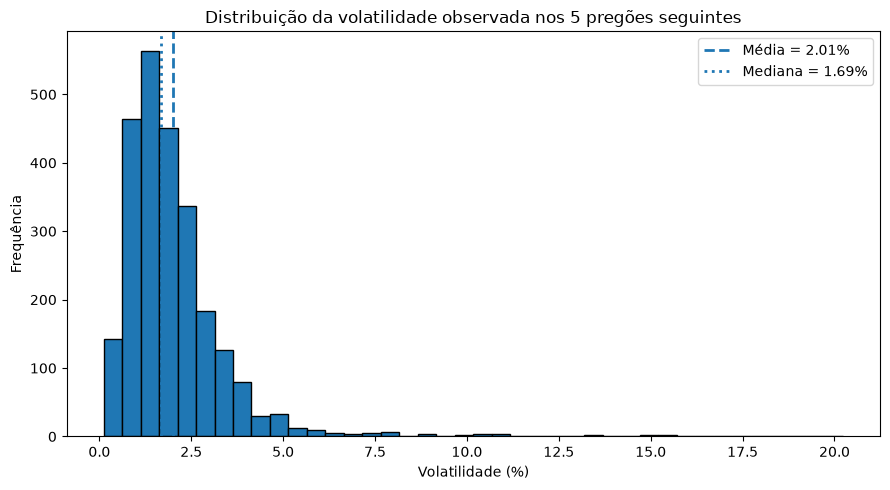

In [8]:
# =========================================================
# VARIÁVEL-ALVO: VOLATILIDADE OBSERVADA NOS 5 PREGÕES SEGUINTES
# =========================================================

# Retornos logarítmicos dos cinco pregões seguintes
# Estas colunas são temporárias e servem somente para calcular o alvo.
retornos_futuros = pd.concat(
    [
        petr4_feat["PETR4_Retorno"].shift(-i)
        for i in range(1, HORIZONTE_PREVISAO + 1)
    ],
    axis=1
)

retornos_futuros.columns = [
    f"Retorno_t+{i}"
    for i in range(1, HORIZONTE_PREVISAO + 1)
]

# ---------------------------------------------------------
# Volatilidade observada nos cinco pregões seguintes
# ---------------------------------------------------------

# skipna=False garante que o alvo só seja calculado quando
# os cinco retornos futuros estiverem disponíveis.
petr4_feat["PETR4_Vol_Observada_5d"] = (
    retornos_futuros
    .std(axis=1, ddof=0, skipna=False) #ddof: desvio-padrão da população/janela inteira; ddof=1: desvio-padrão amostral, com correção de Bessel.
    * 100
)

# =========================================================
# VERIFICAÇÃO
# =========================================================

print("VARIÁVEL-ALVO - PETR4")
print("=" * 70)

print(f"Quantidade total de registros: {len(petr4_feat)}")

print(
    "Alvos válidos:",
    petr4_feat["PETR4_Vol_Observada_5d"].notna().sum()
)

print(
    "Alvos ausentes:",
    petr4_feat["PETR4_Vol_Observada_5d"].isna().sum()
)

# ---------------------------------------------------------
# Verificação das primeiras observações
# ---------------------------------------------------------

print("\nPrimeiras observações:")

verificacao_alvo = pd.concat(
    [
        petr4_feat[["PETR4_Retorno"]],
        retornos_futuros,
        petr4_feat[["PETR4_Vol_Observada_5d"]]
    ],
    axis=1
)

display(verificacao_alvo.head(10))

# ---------------------------------------------------------
# Verificação do final da série
# ---------------------------------------------------------

print("\nÚltimas observações:")

display(verificacao_alvo.tail(10))

# ---------------------------------------------------------
# Estatísticas descritivas do alvo
# ---------------------------------------------------------

print("\nEstatísticas descritivas do alvo (%):")

display(
    petr4_feat["PETR4_Vol_Observada_5d"].describe()
)

# =========================================================
# DISTRIBUIÇÃO DA VARIÁVEL-ALVO
# =========================================================

alvo_plot = (
    petr4_feat["PETR4_Vol_Observada_5d"]
    .dropna()
)

media_alvo = alvo_plot.mean()
mediana_alvo = alvo_plot.median()

plt.figure(figsize=(9, 5))

plt.hist(
    alvo_plot,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    media_alvo,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_alvo:.2f}%"
)

plt.axvline(
    mediana_alvo,
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {mediana_alvo:.2f}%"
)

plt.title(
    "Distribuição da volatilidade observada nos 5 pregões seguintes"
)

plt.xlabel("Volatilidade (%)")
plt.ylabel("Frequência")

plt.legend()
plt.tight_layout()
plt.show()

### Síntese da etapa

Foram obtidos **2.476 alvos válidos**.

Os últimos cinco registros não possuem alvo porque não existem cinco pregões posteriores disponíveis.

A variável-alvo apresenta média próxima de **2,01%**, com períodos extremos de volatilidade muito superior à média,  chegando até aproximadamente 20,23%.

## 8. Integração temporal PETR4 + Brent

A PETR4 foi usada como calendário de referência.

Para cada pregão da PETR4, foi associada a informação mais recente disponível do Brent, utilizando uma defasagem conservadora antes da integração.

Como medida conservadora contra *look-ahead bias*, os atributos do Brent serão
defasados em uma observação antes da integração.

Objetivos:

- preservar os pregões da PETR4;
- evitar informação futura;
- respeitar as diferenças de calendário entre os mercados.

INTEGRAÇÃO PETR4 + BRENT
Registros PETR4 antes da integração: 2481
Registros após a integração: 2481

Verificação temporal:
Informações do Brent provenientes do futuro: 0

Defasagem da informação do Brent em dias:


count    2480.000000
mean        1.487097
std         0.948787
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         6.000000
Name: BRENT_Defasagem_Dias, dtype: float64

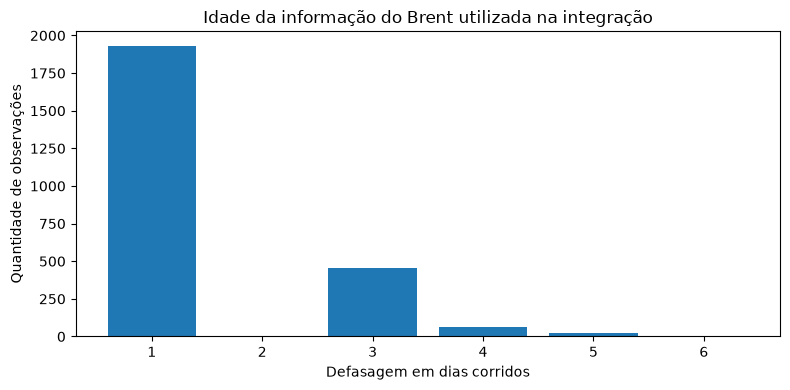


Exemplo da integração:


,Date,PETR4_Close,PETR4_HV30_Pct,BRENT_Data_Origem,BRENT_Retorno_Pct,BRENT_HV30_Pct,BRENT_Defasagem_Dias,PETR4_Vol_Observada_5d
0,2016-01-04,1.721011,NaN,NaT,NaN,NaN,NaN,1.452946
1,2016-01-05,1.673414,NaN,2016-01-04,NaN,NaN,1.0,3.267848
2,2016-01-06,1.603270,NaN,2016-01-05,-1.984564,NaN,1.0,3.291183
3,2016-01-07,1.568199,NaN,2016-01-06,-4.696288,NaN,1.0,5.750067
4,2016-01-08,1.570704,NaN,2016-01-07,-0.944231,NaN,1.0,6.339473
5,2016-01-11,1.525612,NaN,2016-01-08,-5.659815,NaN,3.0,6.460740
6,2016-01-12,1.385326,NaN,2016-01-11,-4.831070,NaN,1.0,5.985659
7,2016-01-13,1.320193,NaN,2016-01-12,-3.317850,NaN,1.0,5.997890
8,2016-01-14,1.425408,NaN,2016-01-13,-1.921757,NaN,1.0,3.839880
9,2016-01-15,1.295142,NaN,2016-01-14,0.909727,NaN,1.0,3.016653


In [9]:
# =========================================================
# INTEGRAÇÃO TEMPORAL PETR4 + BRENT
# =========================================================

# Atributos do Brent que serão utilizados na integração
colunas_brent = [
    "BRENT_Retorno",
    "BRENT_Retorno_Pct",
    "BRENT_HV30",
    "BRENT_HV30_Pct"
]

# ---------------------------------------------------------
# Preparação do Brent com defasagem conservadora
# ---------------------------------------------------------

brent_integracao = brent_feat[colunas_brent].copy()

# Guarda a data real de origem das informações
brent_integracao["BRENT_Data_Origem"] = brent_integracao.index

# Defasa os atributos em uma observação
# A linha da data atual passa a carregar informação
# proveniente da observação anterior do Brent.
brent_integracao[
    colunas_brent + ["BRENT_Data_Origem"]
] = brent_integracao[
    colunas_brent + ["BRENT_Data_Origem"]
].shift(1)

# Data usada como referência para a integração
brent_integracao = (
    brent_integracao
    .reset_index()
    .rename(columns={"Date": "BRENT_Data_Integracao"})
    .sort_values("BRENT_Data_Integracao")
)



# ---------------------------------------------------------
# Preparação da PETR4
# ---------------------------------------------------------

petr4_integracao = (
    petr4_feat
    .reset_index()
    .sort_values("Date")
)

# ---------------------------------------------------------
# Padronização dos tipos de data
# ---------------------------------------------------------

petr4_integracao["Date"] = (
    petr4_integracao["Date"].astype("datetime64[ns]")
)

brent_integracao["BRENT_Data_Integracao"] = (
    brent_integracao["BRENT_Data_Integracao"].astype("datetime64[ns]")
)

brent_integracao["BRENT_Data_Origem"] = (
    brent_integracao["BRENT_Data_Origem"].astype("datetime64[ns]")
)

# ---------------------------------------------------------
# Integração temporal
# ---------------------------------------------------------

# Para cada data da PETR4, busca a última linha do Brent
# cuja data de integração seja menor ou igual à data da PETR4.
dados_integrados = pd.merge_asof(
    petr4_integracao,
    brent_integracao,
    left_on="Date",
    right_on="BRENT_Data_Integracao",
    direction="backward"
)

# ---------------------------------------------------------
# Idade da informação do Brent
# ---------------------------------------------------------

dados_integrados["BRENT_Defasagem_Dias"] = (
    dados_integrados["Date"]
    - dados_integrados["BRENT_Data_Origem"]
).dt.days

# =========================================================
# VERIFICAÇÕES
# =========================================================

print("INTEGRAÇÃO PETR4 + BRENT")
print("=" * 70)

print(
    f"Registros PETR4 antes da integração: "
    f"{len(petr4_feat)}"
)

print(
    f"Registros após a integração: "
    f"{len(dados_integrados)}"
)

# print("\nDisponibilidade dos atributos do Brent:")

# print(
#     dados_integrados[
#         [
#             "BRENT_Retorno",
#             "BRENT_HV30"
#         ]
#     ].notna().sum()
# )

# ---------------------------------------------------------
# Verificação de look-ahead
# ---------------------------------------------------------

uso_futuro = (
    dados_integrados["BRENT_Data_Origem"]
    > dados_integrados["Date"]
).sum()

print("\nVerificação temporal:")

print(
    "Informações do Brent provenientes do futuro:",
    uso_futuro
)

# ---------------------------------------------------------
# Defasagem temporal
# ---------------------------------------------------------

print("\nDefasagem da informação do Brent em dias:")

display(
    dados_integrados["BRENT_Defasagem_Dias"].describe()
)

# =========================================================
# DISTRIBUIÇÃO DA DEFASAGEM DO BRENT
# =========================================================

defasagem_brent = (
    dados_integrados["BRENT_Defasagem_Dias"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))

plt.bar(
    defasagem_brent.index,
    defasagem_brent.values
)

plt.title(
    "Idade da informação do Brent utilizada na integração"
)

plt.xlabel("Defasagem em dias corridos")
plt.ylabel("Quantidade de observações")

plt.xticks(defasagem_brent.index)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Exemplo da integração
# ---------------------------------------------------------

print("\nExemplo da integração:")

display(
    dados_integrados[
        [
            "Date",
            "PETR4_Close",
            "PETR4_HV30_Pct",
            "BRENT_Data_Origem",
            "BRENT_Retorno_Pct",
            "BRENT_HV30_Pct",
            "BRENT_Defasagem_Dias",
            "PETR4_Vol_Observada_5d"
        ]
    ].head(40)
)

### Síntese da etapa

A integração preservou os **2.481 pregões válidos da PETR4** e não encontrou uso de informação futura do Brent.

Em pelo menos 75% das observações, a informação utilizada possuía
defasagem de apenas 1 dia. 

A maior defasagem observada foi de 6 dias, decorrente
de diferenças de calendário, fins de semana ou feriados.

As janelas `HV30` das duas séries possuem 30 observações, mas podem cobrir durações diferentes em dias corridos.

## 9. Base supervisionada final

Nesta etapa será construída a base utilizada posteriormente nos modelos de
regressão.

A base de modelagem reúne:

**PETR4**
- retorno: variação logarítmica entre o fechamento do dia atual e o fechamento do dia anterior;
- amplitude: variação logarítmica entre a máxima e a mínima do mesmo dia;
- variação do volume: variação logaritmica do volume do dia anterior e do dia atual;
- volatilidade histórica de 30 pregões (HV30): desvio-padrão calculado sobre os retornos dos últimos 30 pregões.

**Brent**
- retorno;
- volatilidade histórica de 30 observações (HV30).

**Alvo**
- volatilidade (desvio-padrão) observada da PETR4 nos 5 pregões seguintes (%).

As representações percentuais auxiliares não entram nos modelos.

In [10]:
# =========================================================
# BASE SUPERVISIONADA FINAL
# =========================================================

# ---------------------------------------------------------
# Atributos utilizados efetivamente na modelagem
# ---------------------------------------------------------

atributos_petr4 = [
    "PETR4_Retorno",
    "PETR4_Amplitude",
    "PETR4_Var_Volume",
    "PETR4_HV30"
]

atributos_brent = [
    "BRENT_Retorno",
    "BRENT_HV30"
]

# ---------------------------------------------------------
# Colunas percentuais - apenas para interpretação
# ---------------------------------------------------------

colunas_percentuais = [
    "PETR4_Retorno_Pct",
    "PETR4_Var_Volume_Pct",
    "PETR4_HV30_Pct",
    "BRENT_Retorno_Pct",
    "BRENT_HV30_Pct"
]

# ---------------------------------------------------------
# Variável-alvo
# ---------------------------------------------------------

alvo = "PETR4_Vol_Observada_5d"

# ---------------------------------------------------------
# Colunas para auditoria temporal
# ---------------------------------------------------------

colunas_auditoria = [
    "Date",
    "BRENT_Data_Origem",
    "BRENT_Defasagem_Dias"
]

# ---------------------------------------------------------
# Seleção da base
# ---------------------------------------------------------

base_supervisionada = dados_integrados[
    colunas_auditoria
    + atributos_petr4
    + atributos_brent
    + colunas_percentuais
    + [alvo]
].copy()

quantidade_antes = len(base_supervisionada)

# ---------------------------------------------------------
# Colunas obrigatórias para a modelagem
# ---------------------------------------------------------

# IMPORTANTE:
# As colunas percentuais NÃO entram nesta lista.
colunas_modelagem = (
    atributos_petr4
    + atributos_brent
    + [alvo]
)

# Remove somente observações sem os dados necessários
# para os experimentos de modelagem.
base_supervisionada = (
    base_supervisionada
    .dropna(subset=colunas_modelagem)
    .reset_index(drop=True)
)

quantidade_depois = len(base_supervisionada)

# =========================================================
# VERIFICAÇÕES
# =========================================================

print("BASE SUPERVISIONADA FINAL")
print("=" * 75)

print(f"Registros antes:     {quantidade_antes}")
print(f"Registros depois:    {quantidade_depois}")
print(f"Registros removidos: {quantidade_antes - quantidade_depois}")

print(
    f"\nPeríodo final: "
    f"{base_supervisionada['Date'].min().date()} a "
    f"{base_supervisionada['Date'].max().date()}"
)

# ---------------------------------------------------------
# Valores ausentes
# ---------------------------------------------------------

print("\nValores ausentes nas colunas de modelagem:")

print(
    base_supervisionada[
        colunas_modelagem
    ].isna().sum()
)

# ---------------------------------------------------------
# Validações temporais
# ---------------------------------------------------------

print("\nDatas duplicadas:")
print(
    base_supervisionada["Date"].duplicated().sum()
)

print("\nInformações do Brent provenientes do futuro:")
print(
    (
        base_supervisionada["BRENT_Data_Origem"]
        > base_supervisionada["Date"]
    ).sum()
)

# ---------------------------------------------------------
# Configuração dos experimentos
# ---------------------------------------------------------

print("\nAtributos do experimento PETR4:")
print(atributos_petr4)

print("\nAtributos adicionais do experimento PETR4 + Brent:")
print(atributos_brent)

print("\nColunas percentuais mantidas apenas para interpretação:")
print(colunas_percentuais)

print("\nVariável-alvo:")
print(alvo)

# ---------------------------------------------------------
# Visualização didática
# ---------------------------------------------------------

print("\nPrimeiras observações:")

display(
    base_supervisionada[
        [
            "Date",

            "PETR4_Retorno",
            "PETR4_Retorno_Pct",

            "PETR4_Var_Volume",
            "PETR4_Var_Volume_Pct",

            "PETR4_HV30",
            "PETR4_HV30_Pct",

            "BRENT_Retorno",
            "BRENT_Retorno_Pct",

            "BRENT_HV30",
            "BRENT_HV30_Pct",

            "PETR4_Vol_Observada_5d"
        ]
    ].head(10)
)

BASE SUPERVISIONADA FINAL
Registros antes:     2481
Registros depois:    2446
Registros removidos: 35

Período final: 2016-02-18 a 2025-12-19

Valores ausentes nas colunas de modelagem:
PETR4_Retorno             0
PETR4_Amplitude           0
PETR4_Var_Volume          0
PETR4_HV30                0
BRENT_Retorno             0
BRENT_HV30                0
PETR4_Vol_Observada_5d    0
dtype: int64

Datas duplicadas:
0

Informações do Brent provenientes do futuro:
0

Atributos do experimento PETR4:
['PETR4_Retorno', 'PETR4_Amplitude', 'PETR4_Var_Volume', 'PETR4_HV30']

Atributos adicionais do experimento PETR4 + Brent:
['BRENT_Retorno', 'BRENT_HV30']

Colunas percentuais mantidas apenas para interpretação:
['PETR4_Retorno_Pct', 'PETR4_Var_Volume_Pct', 'PETR4_HV30_Pct', 'BRENT_Retorno_Pct', 'BRENT_HV30_Pct']

Variável-alvo:
PETR4_Vol_Observada_5d

Primeiras observações:


,Date,PETR4_Retorno,PETR4_Retorno_Pct,PETR4_Var_Volume,PETR4_Var_Volume_Pct,PETR4_HV30,PETR4_HV30_Pct,BRENT_Retorno,BRENT_Retorno_Pct,BRENT_HV30,BRENT_HV30_Pct,PETR4_Vol_Observada_5d
0,2016-02-18,-0.019418,-1.923061,-0.261632,-23.020583,0.049283,4.928252,0.065965,6.818913,0.042970,4.296963,5.598655
1,2016-02-19,-0.028731,-2.832253,-0.148896,-13.834121,0.049289,4.928945,-0.000301,-0.030111,0.042119,4.211877,5.313868
2,2016-02-22,0.122257,13.004476,0.357999,43.046349,0.054630,5.463032,-0.047496,-4.638554,0.042928,4.292835,2.665717
3,2016-02-23,-0.024098,-2.380955,0.059188,6.097419,0.054649,5.464857,0.059174,6.096020,0.042969,4.296946,2.426718
4,2016-02-24,-0.010215,-1.016270,-0.125074,-11.756827,0.054620,5.462034,-0.051622,-5.031259,0.043055,4.305513,2.623632
5,2016-02-25,0.004098,0.410690,-0.063914,-6.191389,0.054526,5.452606,-0.012618,-1.253918,0.042637,4.263733,5.129202
6,2016-02-26,-0.004098,-0.409010,-0.136746,-12.780831,0.051953,5.195250,0.041355,4.222222,0.042986,4.298584,4.116119
7,2016-02-29,0.053959,5.544153,0.315421,37.083692,0.052307,5.230741,0.085487,8.924764,0.045372,4.537194,4.694575
8,2016-03-01,0.032539,3.307415,-0.039081,-3.832710,0.050703,5.070256,0.004464,0.447427,0.045347,4.534731,5.063073
9,2016-03-02,0.062063,6.402965,0.089822,9.397918,0.048883,4.888285,-0.005304,-0.528953,0.044099,4.409862,5.473411


### Síntese da etapa

Os modelos PETR4 e PETR4 + Brent utilizam:

- as **mesmas datas**;
- o **mesmo alvo**;
- a mesma metodologia temporal.

A única diferença entre eles é a inclusão das duas variáveis do Brent.

### Formação da base supervisionada

| Etapa | Registros | Motivo |
|---|---:|---|
| PETR4 original | 2.491 | Base coletada |
| Após limpeza | 2.481 | -10 sem negociação |
| Base supervisionada | **2.446** | -30 iniciais para HV30 e -5 finais sem alvo |

Assim, a redução de registros decorre das regras de qualidade e da própria construção temporal das variáveis.

```text
PETR4 original                         2.491
   │
   ├── 10 registros com volume zero
   ↓
PETR4 limpa                            2.481
   │
   ├── 30 observações iniciais sem histórico
   │   suficiente para cálculo da HV30
   │
   ├── 5 observações finais sem os 5 pregões
   │   seguintes necessários para calcular o alvo
   ↓
BASE SUPERVISIONADA                    2.446
```

## 10. Preparação da avaliação temporal com Walk-Forward (Criação do protocolo)

Criação da base específica para o processo incluindo o baseline, considerando a volatilidade dos últimos 30 pregões, que será comparada nos passos seguintes.

Dessa forma, o baseline utiliza a mesma janela histórica principal adotada no experimento:

**30 pregões passados → volatilidade dos 5 pregões seguintes.**

Foram definidos os períodos, as regras temporais e a estrutura necessária para o Walk-Forward.

Foi definido o protocolo de **Walk-Forward com janela expansiva**:

- **2016:** formação do histórico inicial;
- **2017–2023:** desenvolvimento e avaliação histórica;
- **2024–2025:** teste final reservado.

Em cada previsão:

1. somente dados já disponíveis podem entrar no treinamento;
2. o alvo da observação de treino precisa estar completamente conhecido;
3. o `StandardScaler` é reajustado;
4. os modelos são novamente treinados;
5. é prevista a volatilidade dos 5 pregões seguintes.

A regra `PETR4_Alvo_Fim < data_previsao` protege contra vazamento temporal.

PROTOCOLO TEMPORAL WALK-FORWARD
Base supervisionada: 2446 observações

Avaliação histórica: 2017-01-02 a 2023-12-20
Observações históricas a prever: 1726

Teste final: 2024-01-02 a 2025-12-19
Observações de teste a prever: 496

Observações protegidas na fronteira: 5


,Date,PETR4_Alvo_Fim
1945,2023-12-21,2024-01-02
1946,2023-12-22,2024-01-03
1947,2023-12-26,2024-01-04
1948,2023-12-27,2024-01-05
1949,2023-12-28,2024-01-08



Baseline: HV30 dos últimos 30 pregões -> volatilidade dos 5 pregões seguintes
Valores ausentes no baseline HV30: 0


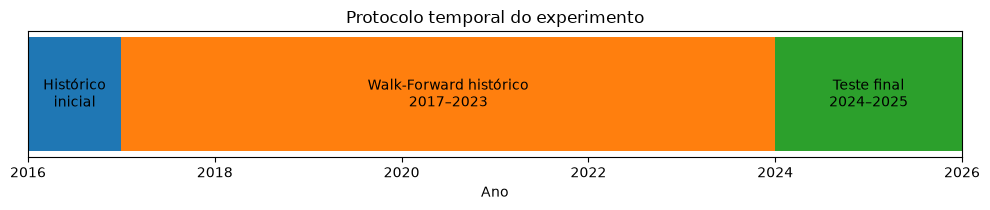

In [11]:
# =========================================================
# PASSO 10 - PROTOCOLO TEMPORAL WALK-FORWARD
# =========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# =========================================================
# 1. BASE ORDENADA
# =========================================================

base_wf = (
    base_supervisionada
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)


# =========================================================
# 2. DATA FINAL DO ALVO
# =========================================================
#
# Cada alvo utiliza t+1 ... t+5.
# Esta coluna registra a data correspondente a t+5.
# =========================================================

datas_petr4 = pd.Series(
    petr4_feat.index,
    index=petr4_feat.index
)

data_fim_alvo = datas_petr4.shift(
    -HORIZONTE_PREVISAO
)

base_wf["PETR4_Alvo_Fim"] = (
    base_wf["Date"]
    .map(data_fim_alvo)
)


# =========================================================
# 3. BASELINE HV30
# =========================================================
#
# O baseline utiliza a volatilidade histórica dos
# últimos 30 pregões como previsão da volatilidade
# dos 5 pregões seguintes.
#
# A PETR4_HV30 já foi calculada anteriormente na
# engenharia de atributos. Aqui criamos apenas sua
# versão percentual para manter a mesma escala do alvo.
# =========================================================

petr4_feat["PETR4_HV30_Pct"] = (
    petr4_feat["PETR4_HV30"] * 100
)

base_wf["PETR4_HV30_Pct"] = (
    base_wf["Date"]
    .map(
        petr4_feat["PETR4_HV30_Pct"]
    )
)


# =========================================================
# 4. ATRIBUTOS
# =========================================================

atributos_petr4_brent = (
    atributos_petr4
    + atributos_brent
)


# =========================================================
# 5. PERÍODOS DA AVALIAÇÃO
# =========================================================

DATA_INICIO_WF_HIST = pd.Timestamp(
    "2017-01-01"
)

DATA_INICIO_TESTE = pd.Timestamp(
    "2024-01-01"
)


# ---------------------------------------------------------
# Proteção da fronteira entre desenvolvimento e teste
# ---------------------------------------------------------
#
# Algumas observações do final de 2023 possuem alvo
# calculado com pregões de 2024.
#
# Essas observações não podem fazer parte da avaliação
# histórica, pois utilizariam informações pertencentes
# ao período reservado para teste.
# ---------------------------------------------------------

fronteira_protegida = (
    base_wf[
        (base_wf["Date"] < DATA_INICIO_TESTE)
        &
        (
            base_wf["PETR4_Alvo_Fim"]
            >= DATA_INICIO_TESTE
        )
    ]
    .copy()
)


# ---------------------------------------------------------
# Avaliação histórica
# ---------------------------------------------------------

periodo_wf_historico = (
    base_wf[
        (base_wf["Date"] >= DATA_INICIO_WF_HIST)
        &
        (base_wf["Date"] < DATA_INICIO_TESTE)
        &
        (
            base_wf["PETR4_Alvo_Fim"]
            < DATA_INICIO_TESTE
        )
    ]
    .copy()
)


# ---------------------------------------------------------
# Teste final
# ---------------------------------------------------------

periodo_teste_final = (
    base_wf[
        base_wf["Date"] >= DATA_INICIO_TESTE
    ]
    .copy()
)


# =========================================================
# 6. FUNÇÃO DE AVALIAÇÃO
# =========================================================

def calcular_metricas(
    y_real,
    y_previsto
):

    rmse = np.sqrt(
        mean_squared_error(
            y_real,
            y_previsto
        )
    )

    mae = mean_absolute_error(
        y_real,
        y_previsto
    )

    r2 = r2_score(
        y_real,
        y_previsto
    )

    bias = np.mean(
        np.asarray(y_previsto)
        -
        np.asarray(y_real)
    )

    return (
        float(rmse),
        float(mae),
        float(r2),
        float(bias)
    )


# =========================================================
# 7. RESUMO DO PROTOCOLO
# =========================================================

print("PROTOCOLO TEMPORAL WALK-FORWARD")
print("=" * 75)

print(
    f"Base supervisionada: "
    f"{len(base_wf)} observações"
)

print(
    f"\nAvaliação histórica: "
    f"{periodo_wf_historico['Date'].min().date()} "
    f"a "
    f"{periodo_wf_historico['Date'].max().date()}"
)

print(
    f"Observações históricas a prever: "
    f"{len(periodo_wf_historico)}"
)

print(
    f"\nTeste final: "
    f"{periodo_teste_final['Date'].min().date()} "
    f"a "
    f"{periodo_teste_final['Date'].max().date()}"
)

print(
    f"Observações de teste a prever: "
    f"{len(periodo_teste_final)}"
)

print(
    f"\nObservações protegidas na fronteira: "
    f"{len(fronteira_protegida)}"
)

if len(fronteira_protegida) > 0:

    display(
        fronteira_protegida[
            [
                "Date",
                "PETR4_Alvo_Fim"
            ]
        ]
    )


# =========================================================
# 8. VERIFICAÇÃO DO NOVO BASELINE
# =========================================================

print(
    "\nBaseline: HV30 dos últimos 30 pregões "
    "-> volatilidade dos 5 pregões seguintes"
)

print(
    "Valores ausentes no baseline HV30: "
    f"{base_wf['PETR4_HV30_Pct'].isna().sum()}"
)


# =========================================================
# LINHA DO TEMPO DO EXPERIMENTO
# =========================================================

plt.figure(figsize=(10, 2.2))

plt.barh(
    0,
    1,
    left=2016
)

plt.barh(
    0,
    7,
    left=2017
)

plt.barh(
    0,
    2,
    left=2024
)

plt.text(
    2016.5,
    0,
    "Histórico\ninicial",
    ha="center",
    va="center"
)

plt.text(
    2020.5,
    0,
    "Walk-Forward histórico\n2017–2023",
    ha="center",
    va="center"
)

plt.text(
    2025,
    0,
    "Teste final\n2024–2025",
    ha="center",
    va="center"
)

plt.xlim(
    2016,
    2026
)

plt.yticks([])

plt.xlabel("Ano")

plt.title(
    "Protocolo temporal do experimento"
)

plt.tight_layout()
plt.show()

### 10.1 Correlação e multicolinearidade

Antes de interpretar os coeficientes, foram avaliadas:

- correlações entre os atributos;
- multicolinearidade por meio do **VIF** (Variance Inflation Factor).

A análise utiliza somente dados anteriores ao teste final.

Essa etapa ajuda a avaliar se a interpretação
dos coeficientes pode ser prejudicada por multicolinearidade elevada.

MATRIZ DE CORRELAÇÃO


,PETR4_Retorno,PETR4_Amplitude,PETR4_Var_Volume,PETR4_HV30,BRENT_Retorno,BRENT_HV30,PETR4_Vol_Observada_5d
PETR4_Retorno,1.000,-0.148,-0.024,-0.007,-0.059,0.046,-0.167
PETR4_Amplitude,-0.148,1.000,0.242,0.523,-0.082,0.191,0.422
PETR4_Var_Volume,-0.024,0.242,1.000,-0.009,-0.036,-0.009,0.015
PETR4_HV30,-0.007,0.523,-0.009,1.000,-0.046,0.450,0.355
BRENT_Retorno,-0.059,-0.082,-0.036,-0.046,1.000,0.073,-0.064
BRENT_HV30,0.046,0.191,-0.009,0.450,0.073,1.000,0.131
PETR4_Vol_Observada_5d,-0.167,0.422,0.015,0.355,-0.064,0.131,1.000


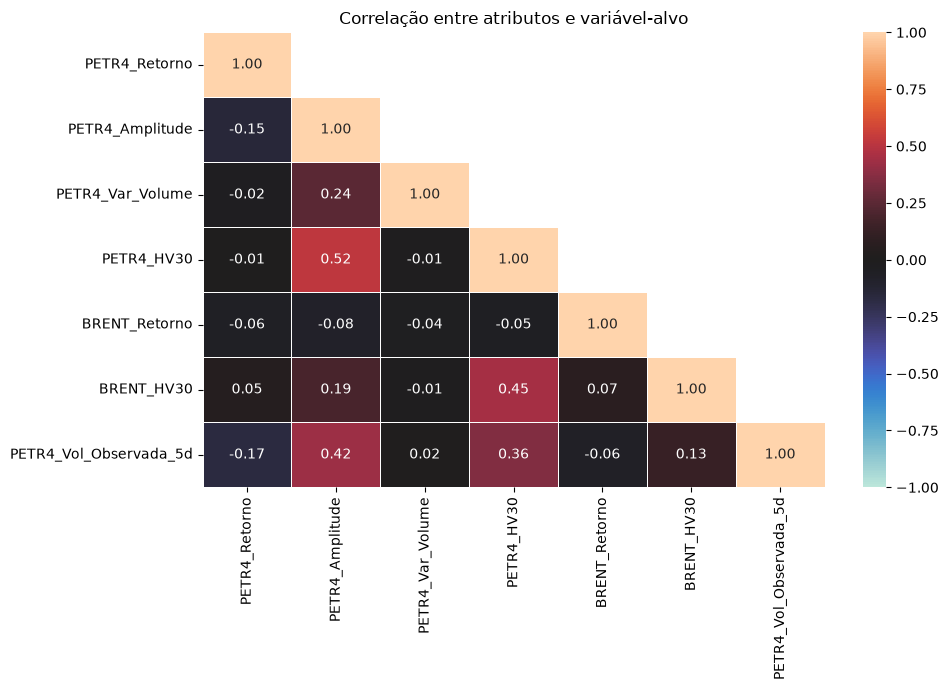


VIF


,Atributo,VIF
0,PETR4_HV30,1.719
1,PETR4_Amplitude,1.559
2,BRENT_HV30,1.274
3,PETR4_Var_Volume,1.093
4,PETR4_Retorno,1.039
5,BRENT_Retorno,1.023


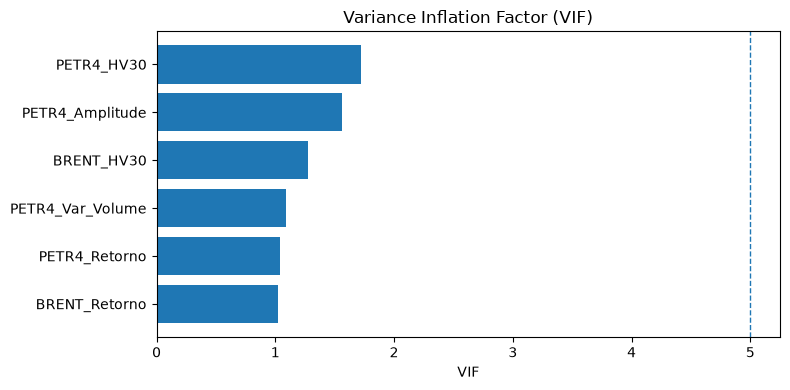

In [12]:
# =========================================================
# CORRELAÇÃO E MULTICOLINEARIDADE
# =========================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.tools.tools import (
    add_constant
)


atributos_modelagem = (
    atributos_petr4
    + atributos_brent
)


dados_desenvolvimento = (
    base_wf[
        (base_wf["Date"] < DATA_INICIO_TESTE)
        &
        (
            base_wf["PETR4_Alvo_Fim"]
            < DATA_INICIO_TESTE
        )
    ]
    .copy()
)


# =========================================================
# CORRELAÇÃO
# =========================================================

matriz_correlacao = (
    dados_desenvolvimento[
        atributos_modelagem
        + [alvo]
    ]
    .corr(method="pearson")
)

print("MATRIZ DE CORRELAÇÃO")
print("=" * 75)

display(
    matriz_correlacao.round(3)
)

# =========================================================
# HEATMAP DE CORRELAÇÃO
# =========================================================

import seaborn as sns

mask = np.triu(
    np.ones_like(
        matriz_correlacao,
        dtype=bool
    ),
    k=1
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    matriz_correlacao,
    mask=mask,
    annot=True,
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Correlação entre atributos e variável-alvo"
)

plt.tight_layout()
plt.show()


# =========================================================
# VIF
# =========================================================

X_vif = (
    dados_desenvolvimento[
        atributos_modelagem
    ]
    .copy()
)

X_vif = add_constant(X_vif)


vif = pd.DataFrame({
    "Atributo":
        X_vif.columns,

    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i
        )
        for i
        in range(X_vif.shape[1])
    ]
})


vif = (
    vif[
        vif["Atributo"] != "const"
    ]
    .sort_values(
        "VIF",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nVIF")
print("=" * 75)

display(
    vif.round(3)
)

# =========================================================
# VIF DOS ATRIBUTOS
# =========================================================

vif_plot = (
    vif
    .sort_values(
        "VIF",
        ascending=True
    )
)

plt.figure(figsize=(8, 4))

plt.barh(
    vif_plot["Atributo"],
    vif_plot["VIF"]
)

plt.axvline(
    5,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Variance Inflation Factor (VIF)"
)

plt.xlabel("VIF")

plt.tight_layout()
plt.show()

### Síntese da etapa

As correlações entre atributos foram moderadas e todos os valores de **VIF ficaram abaixo de 2**.

A maior correlação entre os preditores ocorreu entre a amplitude diária e a
volatilidade histórica da PETR4, seguida pela relação entre as volatilidades
históricas da PETR4 e do Brent.

Não foi identificada multicolinearidade relevante que justificasse remover variáveis antes das regressões.

## 11. Walk-Forward histórico — 2017 a 2023

Serão executadas as previsões:

→ compara com o alvo real dos 5 pregões seguintes

→ calcula as métricas

O ano de 2016 foi utilizado para formar o histórico inicial de treinamento.

A partir de 2017, começamos o processo Walk-Forward, prevendo uma data por vez.

Em cada pregão, treinamos novamente duas regressões lineares: uma usando apenas os atributos da PETR4 e outra usando PETR4 mais Brent.

O modelo recebe somente informações que já estariam disponíveis naquela data e gera uma previsão para a volatilidade dos cinco pregões seguintes.

Depois avançamos um pregão, incorporamos ao treinamento as novas observações cujo alvo já ficou conhecido e repetimos todo o processo.

2024–2025: período reservado para teste final.

Foram comparados:

- **Baseline HV30** — utiliza a volatilidade dos 30 pregões anteriores como previsão para os 5 pregões seguintes;
- **Regressão PETR4**;
- **Regressão PETR4 + Brent**.

O desempenho foi analisado de forma agregada e também ano a ano, utilizando RMSE, MAE, R² e viés médio.

Essa abordagem permite avaliar se o desempenho observado é consistente ao longo
do tempo ou se depende de períodos específicos do mercado.

In [13]:
# =========================================================
# 11. Avaliação histórica com Walk-Forward — 2017 a 2023
# WALK-FORWARD: 2017 A 2023
# =========================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


# =========================================================
# 1. ARMAZENAMENTO DOS RESULTADOS
# =========================================================

resultados_wf_historico = []


# =========================================================
# 2. WALK-FORWARD HISTÓRICO
# =========================================================

for indice in periodo_wf_historico.index:

    linha_atual = (
        periodo_wf_historico.loc[indice]
    )

    data_previsao = (
        linha_atual["Date"]
    )


    # -----------------------------------------------------
    # TREINAMENTO DISPONÍVEL NA DATA
    # -----------------------------------------------------
    #
    # Duas condições:
    #
    # 1. a observação precisa estar no passado;
    # 2. o alvo t+1 ... t+5 precisa estar completamente
    #    conhecido antes da data da previsão.
    # -----------------------------------------------------

    dados_treino_wf = (
        base_wf[
            (base_wf["Date"] < data_previsao)
            &
            (
                base_wf["PETR4_Alvo_Fim"]
                < data_previsao
            )
        ]
        .copy()
    )


    # =====================================================
    # VARIÁVEL-ALVO
    # =====================================================

    y_treino_wf = (
        dados_treino_wf[alvo]
        .copy()
    )


    # =====================================================
    # MODELO 1 - PETR4
    # =====================================================

    X_treino_petr4_wf = (
        dados_treino_wf[
            atributos_petr4
        ]
        .copy()
    )

    X_atual_petr4 = (
        periodo_wf_historico
        .loc[
            [indice],
            atributos_petr4
        ]
        .copy()
    )


    pipeline_petr4_wf = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ])


    pipeline_petr4_wf.fit(
        X_treino_petr4_wf,
        y_treino_wf
    )


    pred_petr4_wf = (
        pipeline_petr4_wf
        .predict(X_atual_petr4)[0]
    )


    # =====================================================
    # MODELO 2 - PETR4 + BRENT
    # =====================================================

    X_treino_brent_wf = (
        dados_treino_wf[
            atributos_petr4_brent
        ]
        .copy()
    )

    X_atual_brent = (
        periodo_wf_historico
        .loc[
            [indice],
            atributos_petr4_brent
        ]
        .copy()
    )


    pipeline_brent_wf = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ])


    pipeline_brent_wf.fit(
        X_treino_brent_wf,
        y_treino_wf
    )


    pred_brent_wf = (
        pipeline_brent_wf
        .predict(X_atual_brent)[0]
    )


    # =====================================================
    # BASELINE HV30
    # =====================================================

    pred_baseline_wf = (
        linha_atual["PETR4_HV30_Pct"]
    )


    # =====================================================
    # AUDITORIA TEMPORAL
    # =====================================================

    ultima_data_treino = (
        dados_treino_wf["Date"].max()
    )

    ultimo_alvo_conhecido = (
        dados_treino_wf[
            "PETR4_Alvo_Fim"
        ].max()
    )


    # =====================================================
    # ARMAZENAMENTO
    # =====================================================

    resultados_wf_historico.append({

        "Date":
            data_previsao,

        "Real":
            linha_atual[alvo],

        "Baseline_HV30":
            pred_baseline_wf,

        "Regressao_PETR4":
            pred_petr4_wf,

        "Regressao_PETR4_Brent":
            pred_brent_wf,

        "N_Treino":
            len(dados_treino_wf),

        "Ultima_Data_Treino":
            ultima_data_treino,

        "Ultimo_Alvo_Conhecido":
            ultimo_alvo_conhecido
    })


# =========================================================
# 3. DATAFRAME FINAL
# =========================================================

resultados_wf_historico = pd.DataFrame(
    resultados_wf_historico
)

resultados_wf_historico["Ano"] = (
    resultados_wf_historico[
        "Date"
    ].dt.year
)


# =========================================================
# 4. AUDITORIA TEMPORAL
# =========================================================

resultados_wf_historico[
    "Violacao_Temporal"
] = (
    resultados_wf_historico[
        "Ultimo_Alvo_Conhecido"
    ]
    >=
    resultados_wf_historico["Date"]
)


colunas_previsao = [
    "Real",
    "Baseline_HV30",
    "Regressao_PETR4",
    "Regressao_PETR4_Brent"
]


print("\nAUDITORIA DO WALK-FORWARD HISTÓRICO")
print("=" * 75)

print(
    f"Previsões produzidas: "
    f"{len(resultados_wf_historico)}"
)

print(
    "Valores ausentes:"
)

print(
    resultados_wf_historico[
        colunas_previsao
    ].isna().sum()
)

print(
    "\nViolações temporais:",
    resultados_wf_historico[
        "Violacao_Temporal"
    ].sum()
)

print(
    f"\nTreino na primeira previsão: "
    f"{resultados_wf_historico['N_Treino'].iloc[0]}"
)

print(
    f"Treino na última previsão: "
    f"{resultados_wf_historico['N_Treino'].iloc[-1]}"
)


# =========================================================
# 5. OBSERVAÇÕES POR ANO
# =========================================================

print("\nOBSERVAÇÕES POR ANO")
print("=" * 75)

observacoes_ano = (
    resultados_wf_historico[
        "Ano"
    ]
    .value_counts()
    .sort_index()
    .rename("Observacoes")
    .to_frame()
)

display(observacoes_ano)


# =========================================================
# 6. MÉTRICAS AGREGADAS - 2017 A 2023
# =========================================================

modelos = {
    "Baseline HV30":
        "Baseline_HV30",

    "Regressão PETR4":
        "Regressao_PETR4",

    "Regressão PETR4 + Brent":
        "Regressao_PETR4_Brent"
}


metricas_historicas = []


for nome_modelo, coluna in modelos.items():

    rmse, mae, r2, bias = calcular_metricas(
        resultados_wf_historico["Real"],
        resultados_wf_historico[coluna]
    )

    metricas_historicas.append({

        "Modelo":
            nome_modelo,

        "RMSE":
            rmse,

        "MAE":
            mae,

        "R2":
            r2,

        "Bias":
            bias
    })


metricas_historicas = pd.DataFrame(
    metricas_historicas
)


print(
    "\nMÉTRICAS AGREGADAS - 2017 A 2023"
)
print("=" * 75)

display(
    metricas_historicas.round(4)
)


# =========================================================
# 7. MÉTRICAS POR ANO
# =========================================================

resultados_anuais = []


for ano in sorted(
    resultados_wf_historico["Ano"].unique()
):

    dados_ano = (
        resultados_wf_historico[
            resultados_wf_historico[
                "Ano"
            ] == ano
        ]
        .copy()
    )


    for nome_modelo, coluna in modelos.items():

        rmse, mae, r2, bias = calcular_metricas(
            dados_ano["Real"],
            dados_ano[coluna]
        )

        resultados_anuais.append({

            "Ano":
                ano,

            "Modelo":
                nome_modelo,

            "Observacoes":
                len(dados_ano),

            "RMSE":
                rmse,

            "MAE":
                mae,

            "R2":
                r2,

            "Bias":
                bias
        })


resultados_anuais = pd.DataFrame(
    resultados_anuais
)


print("\nMÉTRICAS POR ANO")
print("=" * 75)

display(
    resultados_anuais.round(4)
)


# =========================================================
# 8. REDUÇÃO DO RMSE POR ANO
# =========================================================

comparacao_rmse_anual = []


for ano in sorted(
    resultados_wf_historico["Ano"].unique()
):

    dados_ano = (
        resultados_anuais[
            resultados_anuais["Ano"] == ano
        ]
    )


    rmse_baseline_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Baseline HV30",
            "RMSE"
        ]
        .iloc[0]
    )


    rmse_petr4_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Regressão PETR4",
            "RMSE"
        ]
        .iloc[0]
    )


    rmse_brent_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Regressão PETR4 + Brent",
            "RMSE"
        ]
        .iloc[0]
    )


    ganho_petr4 = (
        (
            rmse_baseline_ano
            - rmse_petr4_ano
        )
        / rmse_baseline_ano
    ) * 100


    ganho_brent = (
        (
            rmse_baseline_ano
            - rmse_brent_ano
        )
        / rmse_baseline_ano
    ) * 100


    ganho_brent_vs_petr4 = (
        (
            rmse_petr4_ano
            - rmse_brent_ano
        )
        / rmse_petr4_ano
    ) * 100


    comparacao_rmse_anual.append({

        "Ano":
            ano,

        "PETR4_vs_Baseline_%":
            ganho_petr4,

        "PETR4_Brent_vs_Baseline_%":
            ganho_brent,

        "Brent_vs_PETR4_%":
            ganho_brent_vs_petr4
    })


comparacao_rmse_anual = pd.DataFrame(
    comparacao_rmse_anual
)


print(
    "\nREDUÇÃO PERCENTUAL DO RMSE POR ANO"
)
print("=" * 75)

display(
    comparacao_rmse_anual.round(2)
)


# =========================================================
# 9. TABELA RESUMIDA DE RMSE
# =========================================================

tabela_rmse_historica = (
    resultados_anuais
    .pivot(
        index="Ano",
        columns="Modelo",
        values="RMSE"
    )
)


print("\nRMSE POR ANO")
print("=" * 75)

display(
    tabela_rmse_historica.round(4)
)


AUDITORIA DO WALK-FORWARD HISTÓRICO
Previsões produzidas: 1726
Valores ausentes:
Real                     0
Baseline_HV30            0
Regressao_PETR4          0
Regressao_PETR4_Brent    0
dtype: int64

Violações temporais: 0

Treino na primeira previsão: 214
Treino na última previsão: 1939

OBSERVAÇÕES POR ANO


,Observacoes
Ano,
2017,245
2018,245
2019,248
2020,248
2021,247
2022,250
2023,243



MÉTRICAS AGREGADAS - 2017 A 2023


,Modelo,RMSE,MAE,R2,Bias
0,Baseline HV30,1.7674,1.0678,-0.2782,0.4194
1,Regressão PETR4,1.4393,0.8600,0.1523,0.1253
2,Regressão PETR4 + Brent,1.4666,0.8813,0.1198,0.1026



MÉTRICAS POR ANO


,Ano,Modelo,Observacoes,RMSE,MAE,R2,Bias
0,2017,Baseline HV30,245,1.3868,1.0233,-0.5727,0.4220
1,2017,Regressão PETR4,245,1.2167,0.8536,-0.2105,0.2336
2,2017,Regressão PETR4 + Brent,245,1.2027,0.8297,-0.1828,0.1854
3,2018,Baseline HV30,245,1.9728,1.2659,-0.5253,0.4168
4,2018,Regressão PETR4,245,1.5897,0.9575,0.0095,-0.1002
5,2018,Regressão PETR4 + Brent,245,1.6179,0.9688,-0.0259,-0.2450
6,2019,Baseline HV30,248,0.8892,0.7305,-0.5869,0.3511
7,2019,Regressão PETR4,248,0.7963,0.6730,-0.2725,0.3813
8,2019,Regressão PETR4 + Brent,248,0.8493,0.7164,-0.4477,0.4321
9,2020,Baseline HV30,248,3.1440,1.7684,-0.2741,0.5723



REDUÇÃO PERCENTUAL DO RMSE POR ANO


,Ano,PETR4_vs_Baseline_%,PETR4_Brent_vs_Baseline_%,Brent_vs_PETR4_%
0,2017,12.27,13.28,1.15
1,2018,19.42,17.99,-1.77
2,2019,10.45,4.49,-6.66
3,2020,22.80,20.28,-3.26
4,2021,21.01,20.84,-0.21
5,2022,-3.76,-3.93,-0.17
6,2023,5.79,5.31,-0.52



RMSE POR ANO


Modelo,Baseline HV30,Regressão PETR4,Regressão PETR4 + Brent
Ano,,,
2017,1.3868,1.2167,1.2027
2018,1.9728,1.5897,1.6179
2019,0.8892,0.7963,0.8493
2020,3.1440,2.4272,2.5063
2021,1.9177,1.5148,1.5180
2022,0.9635,0.9997,1.0014
2023,0.8576,0.8079,0.8121


### Resultados históricos

Foram produzidas **1.726 previsões fora da amostra**, com **0 violações temporais**.

| Modelo | RMSE | MAE |
|---|---:|---:|
| Baseline HV30 | 1,7674 | 1,0678 |
| PETR4 | **1,4393** | **0,8600** |
| PETR4 + Brent | 1,4666 | 0,8813 |

A regressão PETR4 reduziu o RMSE em aproximadamente **18,56%** e o MAE em aproximadamente **19,46%** frente ao baseline HV30.

O modelo PETR4 + Brent também superou o baseline, com redução aproximada de **17,02%** no RMSE.

Entretanto, a inclusão das duas variáveis do Brent não apresentou melhoria consistente em relação à regressão PETR4 isolada, apresentando RMSE cerca de **1,90% maior**.

### Estabilidade ao longo dos anos

A regressão PETR4 apresentou RMSE inferior ao baseline HV30 em **6 dos 7 anos** avaliados.

As diferenças anuais de RMSE foram:

| Ano | PETR4 vs Baseline |
|---|---:|
| 2017 | +12,27% |
| 2018 | +19,42% |
| 2019 | +10,45% |
| 2020 | +22,80% |
| 2021 | +21,01% |
| 2022 | -3,76% |
| 2023 | +5,79% |

A vantagem da regressão, portanto, não ficou concentrada em apenas um período.

A principal exceção foi **2022**, quando o baseline HV30 apresentou RMSE de **0,9635**, ligeiramente inferior ao valor de **0,9997** da regressão PETR4.

Em **2020**, a regressão PETR4 apresentou uma das maiores reduções de RMSE frente ao baseline HV30, com melhora de aproximadamente **22,80%**.

Esse resultado mostra que o desempenho relativo varia ao longo do tempo, reforçando a importância de avaliar a estabilidade anual dos modelos.


## 12. Teste final — 2024 a 2025

O período de 2024–2025 foi mantido como **teste final reservado**.

O período foi reservado para avaliação da metodologia. O Walk-Forward permaneceu recursivo: observações do período de teste puderam integrar treinamentos posteriores somente depois que seus respectivos alvos ficaram completamente conhecidos.

A configuração experimental permanece exatamente a mesma utilizada nas etapas
anteriores:

- mesmo baseline HV30;
- mesmos atributos;
- mesmos modelos;
- mesmo Walk-Forward;
- mesma proteção temporal.

Nenhuma decisão adicional foi tomada com base nos resultados do teste.

PERÍODO FINAL DE TESTE
Observações a prever: 496
Período: 2024-01-02 a 2025-12-19

AUDITORIA DO WALK-FORWARD - TESTE
Previsões produzidas: 496

Valores ausentes:
Real                     0
Baseline_HV30            0
Regressao_PETR4          0
Regressao_PETR4_Brent    0
dtype: int64

Violações temporais: 0

MÉTRICAS FINAIS - TESTE 2024 A 2025


,Modelo,RMSE,MAE,R2,Bias
0,Baseline HV30,0.8029,0.6346,-0.5373,0.2949
1,Regressão PETR4,0.7833,0.6487,-0.4631,0.4079
2,Regressão PETR4 + Brent,0.7831,0.6484,-0.4625,0.4122


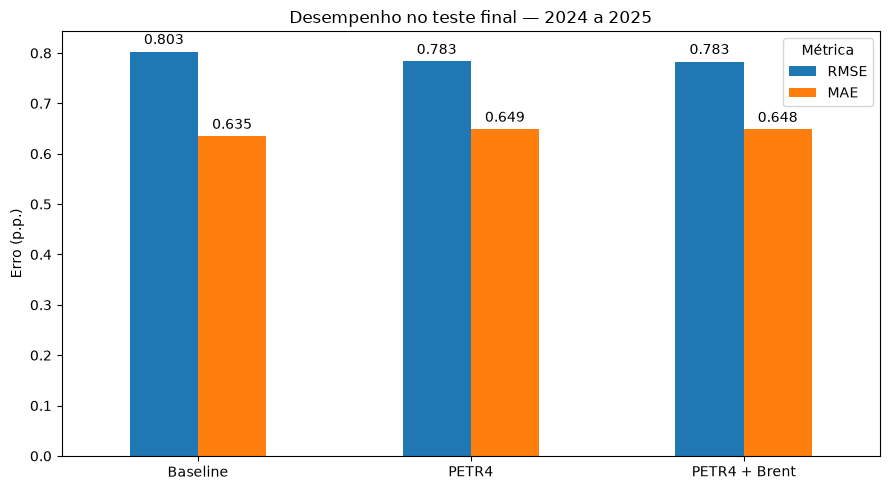


VARIAÇÃO DO RMSE - TESTE
PETR4 vs Baseline: 2.44%
PETR4 + Brent vs Baseline: 2.47%
PETR4 + Brent vs PETR4: 0.02%

MÉTRICAS DO TESTE POR ANO


,Ano,Modelo,Observacoes,RMSE,MAE,R2,Bias
0,2024,Baseline HV30,251,0.8276,0.6506,-0.5809,0.2857
1,2024,Regressão PETR4,251,0.8212,0.6715,-0.5565,0.3968
2,2024,Regressão PETR4 + Brent,251,0.8233,0.6732,-0.5645,0.4021
3,2025,Baseline HV30,245,0.7768,0.6182,-0.5377,0.3043
4,2025,Regressão PETR4,245,0.7424,0.6253,-0.4047,0.4193
5,2025,Regressão PETR4 + Brent,245,0.7397,0.6229,-0.3943,0.4226



REDUÇÃO PERCENTUAL DO RMSE - TESTE POR ANO


,Ano,PETR4_vs_Baseline_%,PETR4_Brent_vs_Baseline_%,Brent_vs_PETR4_%
0,2024,0.77,0.52,-0.26
1,2025,4.42,4.78,0.37



DIAGNÓSTICO DAS PREVISÕES


,Modelo,Menor_Previsao,Maior_Previsao,Previsoes_Negativas
0,Regressão PETR4,1.0187,3.2972,0
1,Regressão PETR4 + Brent,0.9842,3.3121,0


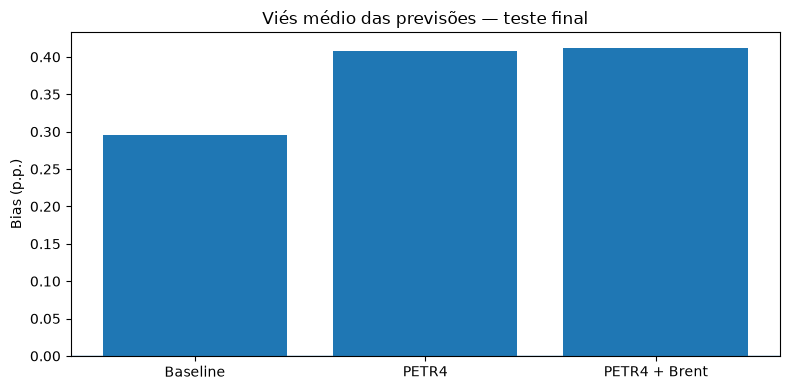

In [14]:
# =========================================================
# 12. Avaliação final no período de teste — 2024 a 2025
# 2024 A 2025
# =========================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


# =========================================================
# 1. PERÍODO DE TESTE
# =========================================================

print("PERÍODO FINAL DE TESTE")
print("=" * 75)

print(
    f"Observações a prever: "
    f"{len(periodo_teste_final)}"
)

print(
    f"Período: "
    f"{periodo_teste_final['Date'].min().date()} "
    f"a "
    f"{periodo_teste_final['Date'].max().date()}"
)


# =========================================================
# 2. ATRIBUTOS
# =========================================================

atributos_petr4_brent = (
    atributos_petr4
    + atributos_brent
)


# =========================================================
# 3. ARMAZENAMENTO
# =========================================================

resultados_teste = []


# =========================================================
# 4. WALK-FORWARD
# =========================================================

for indice in periodo_teste_final.index:

    linha_atual = (
        periodo_teste_final.loc[indice]
    )

    data_previsao = (
        linha_atual["Date"]
    )


    # -----------------------------------------------------
    # DADOS DISPONÍVEIS PARA TREINAMENTO
    # -----------------------------------------------------
    #
    # A observação:
    #
    # 1. deve estar no passado;
    # 2. deve possuir alvo completamente conhecido.
    # -----------------------------------------------------

    dados_treino_wf = (
        base_wf[
            (base_wf["Date"] < data_previsao)
            &
            (
                base_wf["PETR4_Alvo_Fim"]
                < data_previsao
            )
        ]
        .copy()
    )


    # =====================================================
    # VARIÁVEL-ALVO
    # =====================================================

    y_treino_wf = (
        dados_treino_wf[alvo]
        .copy()
    )


    # =====================================================
    # MODELO 1 - PETR4
    # =====================================================

    X_treino_petr4_wf = (
        dados_treino_wf[
            atributos_petr4
        ]
        .copy()
    )

    X_atual_petr4 = (
        periodo_teste_final
        .loc[
            [indice],
            atributos_petr4
        ]
        .copy()
    )


    pipeline_petr4_wf = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ])


    pipeline_petr4_wf.fit(
        X_treino_petr4_wf,
        y_treino_wf
    )


    pred_petr4_wf = (
        pipeline_petr4_wf
        .predict(X_atual_petr4)[0]
    )


    # =====================================================
    # MODELO 2 - PETR4 + BRENT
    # =====================================================

    X_treino_brent_wf = (
        dados_treino_wf[
            atributos_petr4_brent
        ]
        .copy()
    )

    X_atual_brent = (
        periodo_teste_final
        .loc[
            [indice],
            atributos_petr4_brent
        ]
        .copy()
    )


    pipeline_brent_wf = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ])


    pipeline_brent_wf.fit(
        X_treino_brent_wf,
        y_treino_wf
    )


    pred_brent_wf = (
        pipeline_brent_wf
        .predict(X_atual_brent)[0]
    )


    # =====================================================
    # BASELINE HV30
    # =====================================================

    pred_baseline_wf = (
        linha_atual["PETR4_HV30_Pct"]
    )


    # =====================================================
    # AUDITORIA TEMPORAL
    # =====================================================

    ultima_data_treino = (
        dados_treino_wf["Date"].max()
    )

    ultimo_alvo_conhecido = (
        dados_treino_wf[
            "PETR4_Alvo_Fim"
        ].max()
    )


    # =====================================================
    # ARMAZENAMENTO
    # =====================================================

    resultados_teste.append({

        "Date":
            data_previsao,

        "Real":
            linha_atual[alvo],

        "Baseline_HV30":
            pred_baseline_wf,

        "Regressao_PETR4":
            pred_petr4_wf,

        "Regressao_PETR4_Brent":
            pred_brent_wf,

        "N_Treino":
            len(dados_treino_wf),

        "Ultima_Data_Treino":
            ultima_data_treino,

        "Ultimo_Alvo_Conhecido":
            ultimo_alvo_conhecido
    })


# =========================================================
# 5. DATAFRAME FINAL
# =========================================================

resultados_teste = pd.DataFrame(
    resultados_teste
)

resultados_teste["Ano"] = (
    resultados_teste["Date"].dt.year
)


# =========================================================
# 6. AUDITORIA TEMPORAL
# =========================================================

resultados_teste[
    "Violacao_Temporal"
] = (
    resultados_teste[
        "Ultimo_Alvo_Conhecido"
    ]
    >=
    resultados_teste["Date"]
)


colunas_previsao = [
    "Real",
    "Baseline_HV30",
    "Regressao_PETR4",
    "Regressao_PETR4_Brent"
]


print("\nAUDITORIA DO WALK-FORWARD - TESTE")
print("=" * 75)

print(
    f"Previsões produzidas: "
    f"{len(resultados_teste)}"
)

print("\nValores ausentes:")

print(
    resultados_teste[
        colunas_previsao
    ].isna().sum()
)

print(
    "\nViolações temporais:",
    resultados_teste[
        "Violacao_Temporal"
    ].sum()
)

# print(
#     f"\nTreino na primeira previsão: "
#     f"{resultados_teste['N_Treino'].iloc[0]}"
# )

# print(
#     f"Treino na última previsão: "
#     f"{resultados_teste['N_Treino'].iloc[-1]}"
# )


# =========================================================
# 7. MÉTRICAS AGREGADAS
# =========================================================

modelos = {
    "Baseline HV30":
        "Baseline_HV30",

    "Regressão PETR4":
        "Regressao_PETR4",

    "Regressão PETR4 + Brent":
        "Regressao_PETR4_Brent"
}


metricas_teste = []


for nome_modelo, coluna in modelos.items():

    rmse, mae, r2, bias = calcular_metricas(
        resultados_teste["Real"],
        resultados_teste[coluna]
    )

    metricas_teste.append({

        "Modelo":
            nome_modelo,

        "RMSE":
            rmse,

        "MAE":
            mae,

        "R2":
            r2,

        "Bias":
            bias
    })


metricas_teste = pd.DataFrame(
    metricas_teste
)


print(
    "\nMÉTRICAS FINAIS - TESTE 2024 A 2025"
)
print("=" * 75)

display(
    metricas_teste.round(4)
)


# =========================================================
# RMSE E MAE - TESTE FINAL
# =========================================================

metricas_plot = (
    metricas_teste[
        [
            "Modelo",
            "RMSE",
            "MAE"
        ]
    ]
    .copy()
)

nomes_modelos = {
    "Baseline HV30": "Baseline",
    "Regressão PETR4": "PETR4",
    "Regressão PETR4 + Brent": "PETR4 + Brent"
}

metricas_plot["Modelo"] = (
    metricas_plot["Modelo"]
    .replace(nomes_modelos)
)

metricas_plot = (
    metricas_plot
    .set_index("Modelo")
)

ax = metricas_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Desempenho no teste final — 2024 a 2025"
)

ax.set_xlabel("")
ax.set_ylabel("Erro (p.p.)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.legend(
    title="Métrica"
)

plt.tight_layout()
plt.show()


# =========================================================
# 8. VARIAÇÃO DO RMSE
# =========================================================

rmse_baseline_teste = (
    metricas_teste.loc[
        metricas_teste["Modelo"]
        == "Baseline HV30",
        "RMSE"
    ].iloc[0]
)

rmse_petr4_teste = (
    metricas_teste.loc[
        metricas_teste["Modelo"]
        == "Regressão PETR4",
        "RMSE"
    ].iloc[0]
)

rmse_brent_teste = (
    metricas_teste.loc[
        metricas_teste["Modelo"]
        == "Regressão PETR4 + Brent",
        "RMSE"
    ].iloc[0]
)


ganho_petr4_teste = (
    (
        rmse_baseline_teste
        - rmse_petr4_teste
    )
    / rmse_baseline_teste
) * 100


ganho_brent_teste = (
    (
        rmse_baseline_teste
        - rmse_brent_teste
    )
    / rmse_baseline_teste
) * 100


ganho_brent_vs_petr4_teste = (
    (
        rmse_petr4_teste
        - rmse_brent_teste
    )
    / rmse_petr4_teste
) * 100


print("\nVARIAÇÃO DO RMSE - TESTE")
print("=" * 75)

print(
    f"PETR4 vs Baseline: "
    f"{ganho_petr4_teste:.2f}%"
)

print(
    f"PETR4 + Brent vs Baseline: "
    f"{ganho_brent_teste:.2f}%"
)

print(
    f"PETR4 + Brent vs PETR4: "
    f"{ganho_brent_vs_petr4_teste:.2f}%"
)


# =========================================================
# 9. MÉTRICAS POR ANO
# =========================================================

resultados_anuais_teste = []


for ano in sorted(
    resultados_teste["Ano"].unique()
):

    dados_ano = (
        resultados_teste[
            resultados_teste["Ano"] == ano
        ]
        .copy()
    )


    for nome_modelo, coluna in modelos.items():

        rmse, mae, r2, bias = calcular_metricas(
            dados_ano["Real"],
            dados_ano[coluna]
        )

        resultados_anuais_teste.append({

            "Ano":
                ano,

            "Modelo":
                nome_modelo,

            "Observacoes":
                len(dados_ano),

            "RMSE":
                rmse,

            "MAE":
                mae,

            "R2":
                r2,

            "Bias":
                bias
        })


resultados_anuais_teste = pd.DataFrame(
    resultados_anuais_teste
)


print("\nMÉTRICAS DO TESTE POR ANO")
print("=" * 75)

display(
    resultados_anuais_teste.round(4)
)


# =========================================================
# 10. REDUÇÃO DO RMSE POR ANO
# =========================================================

comparacao_rmse_teste = []


for ano in sorted(
    resultados_teste["Ano"].unique()
):

    dados_ano = (
        resultados_anuais_teste[
            resultados_anuais_teste["Ano"] == ano
        ]
    )


    rmse_baseline_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Baseline HV30",
            "RMSE"
        ].iloc[0]
    )

    rmse_petr4_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Regressão PETR4",
            "RMSE"
        ].iloc[0]
    )

    rmse_brent_ano = (
        dados_ano.loc[
            dados_ano["Modelo"]
            == "Regressão PETR4 + Brent",
            "RMSE"
        ].iloc[0]
    )


    comparacao_rmse_teste.append({

        "Ano":
            ano,

        "PETR4_vs_Baseline_%":
            (
                (
                    rmse_baseline_ano
                    - rmse_petr4_ano
                )
                /
                rmse_baseline_ano
            ) * 100,

        "PETR4_Brent_vs_Baseline_%":
            (
                (
                    rmse_baseline_ano
                    - rmse_brent_ano
                )
                /
                rmse_baseline_ano
            ) * 100,

        "Brent_vs_PETR4_%":
            (
                (
                    rmse_petr4_ano
                    - rmse_brent_ano
                )
                /
                rmse_petr4_ano
            ) * 100
    })


comparacao_rmse_teste = pd.DataFrame(
    comparacao_rmse_teste
)


print(
    "\nREDUÇÃO PERCENTUAL DO RMSE - TESTE POR ANO"
)
print("=" * 75)

display(
    comparacao_rmse_teste.round(2)
)


# =========================================================
# 11. DIAGNÓSTICO DAS PREVISÕES
# =========================================================

diagnostico_teste = pd.DataFrame({

    "Modelo": [
        "Regressão PETR4",
        "Regressão PETR4 + Brent"
    ],

    "Menor_Previsao": [
        resultados_teste[
            "Regressao_PETR4"
        ].min(),

        resultados_teste[
            "Regressao_PETR4_Brent"
        ].min()
    ],

    "Maior_Previsao": [
        resultados_teste[
            "Regressao_PETR4"
        ].max(),

        resultados_teste[
            "Regressao_PETR4_Brent"
        ].max()
    ],

    "Previsoes_Negativas": [
        (
            resultados_teste[
                "Regressao_PETR4"
            ] < 0
        ).sum(),

        (
            resultados_teste[
                "Regressao_PETR4_Brent"
            ] < 0
        ).sum()
    ]
})


print("\nDIAGNÓSTICO DAS PREVISÕES")
print("=" * 75)

display(
    diagnostico_teste.round(4)
)


# =========================================================
# BIAS - TESTE FINAL
# =========================================================

bias_plot = (
    metricas_teste[
        [
            "Modelo",
            "Bias"
        ]
    ]
    .copy()
)

bias_plot["Modelo"] = (
    bias_plot["Modelo"]
    .replace(nomes_modelos)
)

plt.figure(figsize=(8, 4))

plt.bar(
    bias_plot["Modelo"],
    bias_plot["Bias"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Viés médio das previsões — teste final"
)

plt.ylabel("Bias (p.p.)")

plt.tight_layout()
plt.show()

### Resultados do teste final

Foram produzidas **496 previsões**, com **0 violações temporais**.

| Modelo | RMSE | MAE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline HV30 | 0,8029 | **0,6346** | -0,5373 | **0,2949** |
| PETR4 | 0,7833 | 0,6487 | -0,4631 | 0,4079 |
| PETR4 + Brent | **0,7831** | 0,6484 | -0,4625 | 0,4122 |

**RMSE:** a regressão PETR4 reduziu o erro em aproximadamente **2,44%** frente ao baseline HV30.

**MAE:** o baseline HV30 apresentou o menor erro absoluto médio.

**Brent:** a diferença entre PETR4 e PETR4 + Brent foi de apenas **0,02% no RMSE**, sem melhoria consistente nas métricas avaliadas.



### Estabilidade em 2024 e 2025

A regressão PETR4 apresentou RMSE inferior ao baseline HV30 nos dois anos do teste:

| Ano | PETR4 vs Baseline |
|---|---:|
| 2024 | +0,77% |
| 2025 | +4,42% |

Em **2024**, os resultados ficaram muito próximos: o RMSE foi de **0,8276** no baseline HV30 e **0,8212** na regressão PETR4.

Em **2025**, a diferença foi mais clara: o RMSE passou de **0,7768** no baseline para **0,7424** na regressão PETR4.

Assim, a vantagem no RMSE foi observada nos dois anos, porém foi pequena em 2024 e mais pronunciada em 2025.

### Contribuição do Brent

No resultado agregado:

- regressão PETR4: RMSE = **0,7833**;
- regressão PETR4 + Brent: RMSE = **0,7831**.

A diferença corresponde a apenas cerca de **0,02%** de melhoria.

Separadamente:

- **2024:** a inclusão do Brent piorou o RMSE em aproximadamente **0,26%**;
- **2025:** a inclusão do Brent melhorou o RMSE em aproximadamente **0,37%**.

As diferenças foram pequenas e apresentaram sinais diferentes entre os anos.

Portanto, no período de teste, as duas representações do Brent utilizadas não apresentaram melhoria consistente nas métricas avaliadas.

### Viés das previsões

Todos os modelos apresentaram viés positivo no teste final:

- Baseline HV30: **+0,2949 p.p.**;
- PETR4: **+0,4079 p.p.**;
- PETR4 + Brent: **+0,4122 p.p.**.

Portanto, todos apresentaram tendência média de superestimação da volatilidade no período.

O baseline apresentou o menor viés entre os três modelos, enquanto as duas regressões apresentaram superestimação média mais elevada.

### R²

Todos os modelos apresentaram R² negativo no período final.

Isso significa que, em erro quadrático, os modelos ficaram abaixo de uma referência retrospectiva constante baseada na média do próprio período de teste.

Os valores foram:

- Baseline HV30: **-0,5373**;
- PETR4: **-0,4631**;
- PETR4 + Brent: **-0,4625**.

As regressões apresentaram R² menos negativo que o baseline, mas nenhum dos modelos superou a referência retrospectiva representada pela média do período.

Como essa média completa não estaria disponível antecipadamente durante uma aplicação real, o R² é tratado como uma métrica complementar à avaliação Walk-Forward.

### Análise visual do teste final

O gráfico permite observar que a regressão PETR4 acompanha parte da dinâmica geral da volatilidade, mas não reproduz perfeitamente a intensidade das oscilações ao longo de todo o período.

Em vários momentos, as previsões permanecem acima dos valores efetivamente observados, o que é coerente com o **Bias positivo** identificado nas métricas do teste.

Assim, o resultado visual reforça a leitura quantitativa já obtida:

- a regressão PETR4 apresentou **RMSE ligeiramente menor** que o baseline HV30;
- porém o **baseline apresentou menor MAE**;
- todos os modelos apresentaram **R² negativo**;
- e as regressões apresentaram **viés positivo mais elevado**.

Portanto, no teste final, a regressão PETR4 apresentou pequena vantagem pelo RMSE, mas não superioridade consistente em todas as métricas.

### Gráfico Real × Previsto no teste final

Além das métricas numéricas, foi construída uma visualização da volatilidade real observada e das previsões geradas no teste final.

O objetivo do gráfico é facilitar a interpretação visual do desempenho dos modelos, permitindo observar:

- se as previsões acompanham a direção geral da volatilidade;
- se os modelos respondem aos picos e quedas;
- se existe tendência sistemática de superestimação ou subestimação;
- se a inclusão do Brent altera visualmente o comportamento das previsões.

Esse gráfico complementa RMSE, MAE, R² e Bias, ajudando a entender qualitativamente o desempenho fora da amostra.

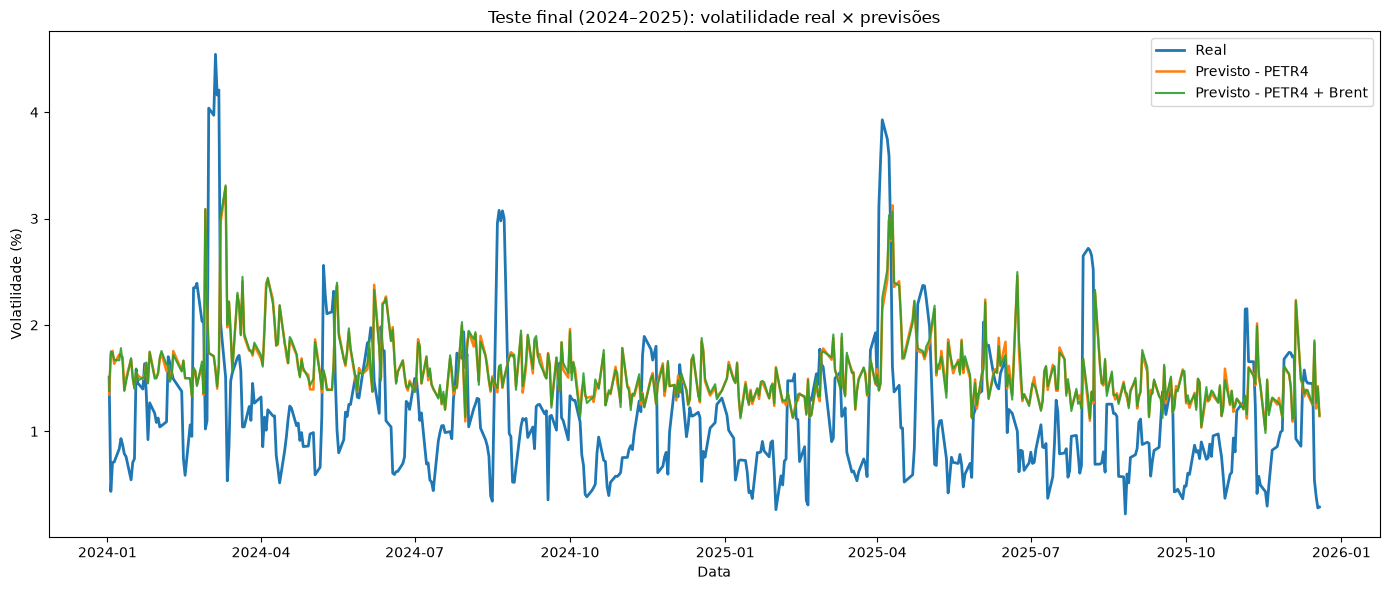

In [15]:
# =========================================================
# GRÁFICO REAL × PREVISTO - TESTE FINAL
# =========================================================

plt.figure(figsize=(14, 6))

plt.plot(
    resultados_teste["Date"],
    resultados_teste["Real"],
    label="Real",
    linewidth=2
)

plt.plot(
    resultados_teste["Date"],
    resultados_teste["Regressao_PETR4"],
    label="Previsto - PETR4",
    linewidth=1.8
)

plt.plot(
    resultados_teste["Date"],
    resultados_teste["Regressao_PETR4_Brent"],
    label="Previsto - PETR4 + Brent",
    linewidth=1.5,
    alpha=0.9
)

plt.title(
    "Teste final (2024–2025): volatilidade real × previsões"
)

plt.xlabel("Data")
plt.ylabel("Volatilidade (%)")

plt.legend()
plt.tight_layout()
plt.show()

### Leitura do gráfico Real × Previsto

O gráfico mostra que a regressão PETR4 acompanha parte da dinâmica geral da volatilidade, mas não reproduz perfeitamente a intensidade das oscilações ao longo de todo o período.

Em vários momentos, as previsões permanecem acima dos valores efetivamente observados, comportamento coerente com o **Bias positivo** identificado no teste final.

A leitura visual é consistente com as métricas:

- a regressão PETR4 apresentou **RMSE ligeiramente menor** que o baseline HV30;
- o **baseline apresentou menor MAE**;
- todos os modelos apresentaram **R² negativo**;
- e as regressões apresentaram **viés positivo mais elevado**.

Portanto, o gráfico reforça que a regressão PETR4 apresentou pequena vantagem pelo RMSE no teste final, mas não superioridade consistente em todas as métricas.


## 13. Consolidação dos resultados — 2017 a 2025

Após a conclusão do teste final, os resultados do Walk-Forward podem ser
analisados conjuntamente ao longo de todo o período de avaliação.

A análise contempla:

- **2017 a 2023:** período histórico utilizado para desenvolvimento e análise
  da estabilidade da metodologia;
- **2024 a 2025:** período reservado para teste final.

Objetivos:

- verificar estabilidade temporal;
- comparar a regressão PETR4 com o **baseline HV30**;
- observar o efeito das variáveis do Brent;
- comparar desenvolvimento e teste final.

CONSOLIDAÇÃO WALK-FORWARD
Total de previsões: 2222
Período: 2017-01-02 a 2025-12-19

OBSERVAÇÕES POR FASE


,Observacoes
Fase,
Histórico 2017-2023,1726
Teste final 2024-2025,496



MÉTRICAS POR ANO - 2017 A 2025


,Ano,Fase,Modelo,Observacoes,RMSE,MAE,R2,Bias
0,2017,Histórico 2017-2023,Baseline HV30,245,1.3868,1.0233,-0.5727,0.4220
1,2017,Histórico 2017-2023,Regressão PETR4,245,1.2167,0.8536,-0.2105,0.2336
2,2017,Histórico 2017-2023,Regressão PETR4 + Brent,245,1.2027,0.8297,-0.1828,0.1854
3,2018,Histórico 2017-2023,Baseline HV30,245,1.9728,1.2659,-0.5253,0.4168
4,2018,Histórico 2017-2023,Regressão PETR4,245,1.5897,0.9575,0.0095,-0.1002
5,2018,Histórico 2017-2023,Regressão PETR4 + Brent,245,1.6179,0.9688,-0.0259,-0.2450
6,2019,Histórico 2017-2023,Baseline HV30,248,0.8892,0.7305,-0.5869,0.3511
7,2019,Histórico 2017-2023,Regressão PETR4,248,0.7963,0.6730,-0.2725,0.3813
8,2019,Histórico 2017-2023,Regressão PETR4 + Brent,248,0.8493,0.7164,-0.4477,0.4321
9,2020,Histórico 2017-2023,Baseline HV30,248,3.1440,1.7684,-0.2741,0.5723



RMSE POR ANO


Modelo,Baseline HV30,Regressão PETR4,Regressão PETR4 + Brent
Ano,,,
2017,1.3868,1.2167,1.2027
2018,1.9728,1.5897,1.6179
2019,0.8892,0.7963,0.8493
2020,3.1440,2.4272,2.5063
2021,1.9177,1.5148,1.5180
2022,0.9635,0.9997,1.0014
2023,0.8576,0.8079,0.8121
2024,0.8276,0.8212,0.8233
2025,0.7768,0.7424,0.7397



REDUÇÃO PERCENTUAL DO RMSE POR ANO


,Ano,Fase,PETR4_vs_Baseline_%,PETR4_Brent_vs_Baseline_%,Brent_vs_PETR4_%
0,2017,Histórico 2017-2023,12.27,13.28,1.15
1,2018,Histórico 2017-2023,19.42,17.99,-1.77
2,2019,Histórico 2017-2023,10.45,4.49,-6.66
3,2020,Histórico 2017-2023,22.80,20.28,-3.26
4,2021,Histórico 2017-2023,21.01,20.84,-0.21
5,2022,Histórico 2017-2023,-3.76,-3.93,-0.17
6,2023,Histórico 2017-2023,5.79,5.31,-0.52
7,2024,Teste final 2024-2025,0.77,0.52,-0.26
8,2025,Teste final 2024-2025,4.42,4.78,0.37


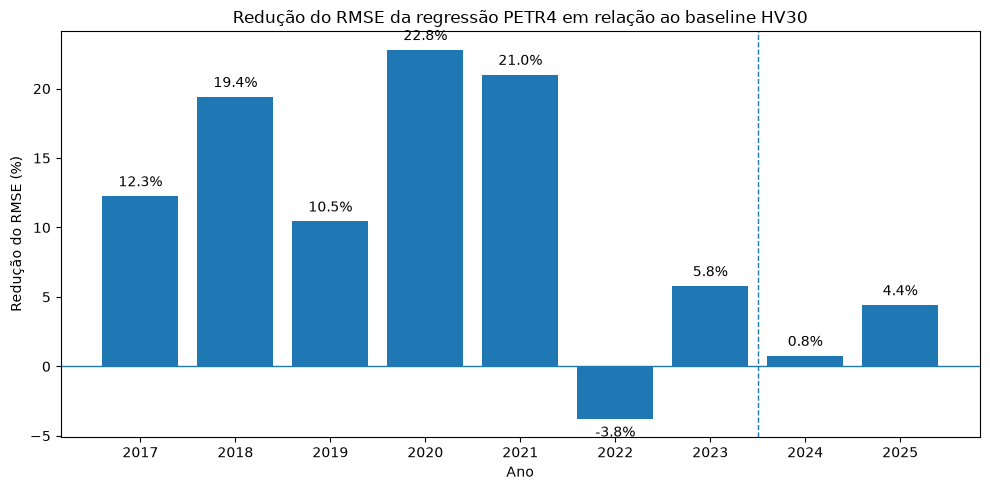


ESTABILIDADE DOS RESULTADOS
Anos em que PETR4 superou o baseline HV30: 8 de 9
Anos em que Brent melhorou a regressão PETR4: 2 de 9

MÉTRICAS AGREGADAS POR FASE


,Fase,Modelo,RMSE,MAE,R2,Bias
0,Histórico 2017-2023,Baseline HV30,1.7674,1.0678,-0.2782,0.4194
1,Histórico 2017-2023,Regressão PETR4,1.4393,0.8600,0.1523,0.1253
2,Histórico 2017-2023,Regressão PETR4 + Brent,1.4666,0.8813,0.1198,0.1026
3,Teste final 2024-2025,Baseline HV30,0.8029,0.6346,-0.5373,0.2949
4,Teste final 2024-2025,Regressão PETR4,0.7833,0.6487,-0.4631,0.4079
5,Teste final 2024-2025,Regressão PETR4 + Brent,0.7831,0.6484,-0.4625,0.4122


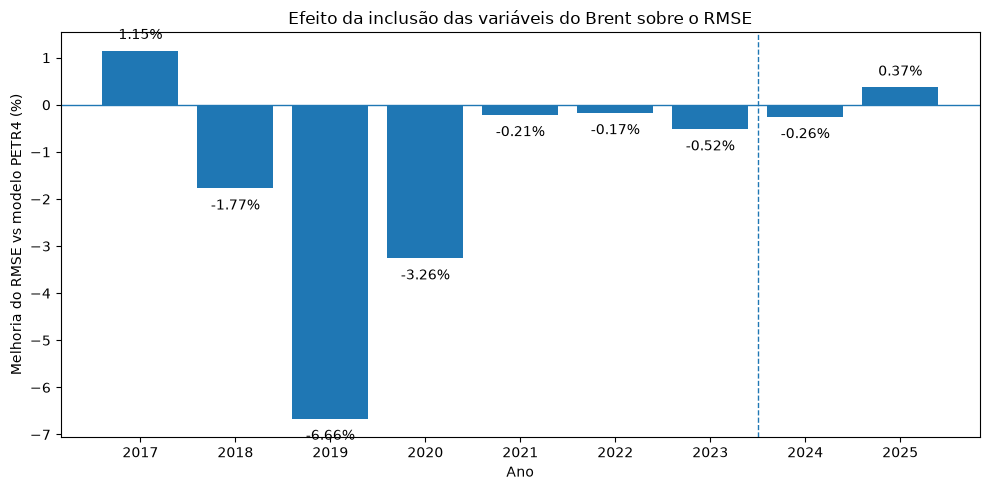

Valores positivos = Brent melhorou o RMSE.
Valores negativos = Brent piorou o RMSE


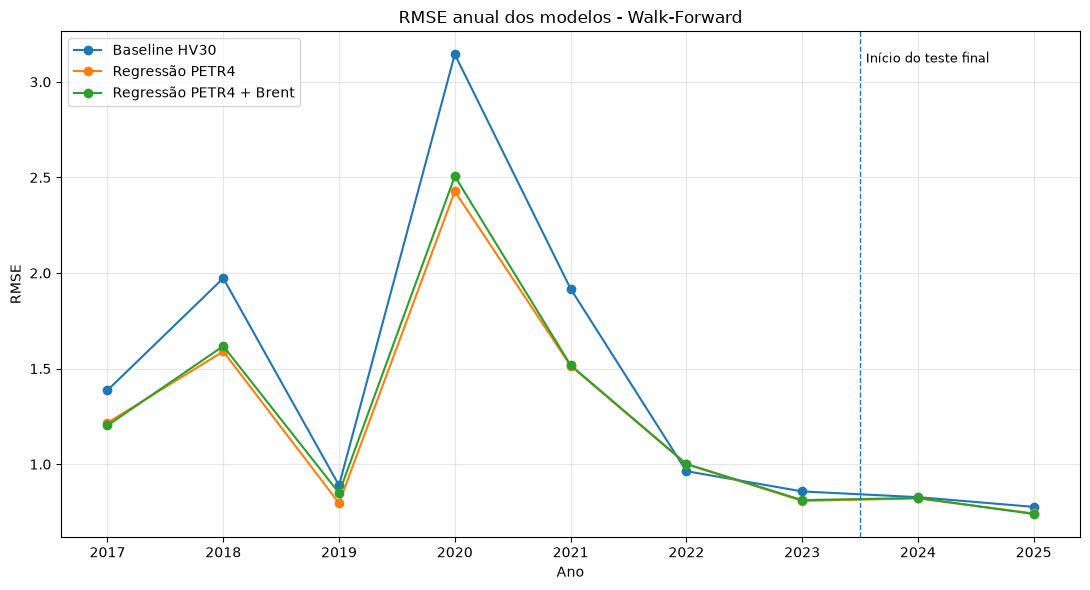

In [16]:
# =========================================================
# PASSO 13 - CONSOLIDAÇÃO TEMPORAL 2017 A 2025
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. IDENTIFICAÇÃO DAS FASES
# =========================================================

historico_final = resultados_wf_historico.copy()
historico_final["Fase"] = "Histórico 2017-2023"

teste_final = resultados_teste.copy()
teste_final["Fase"] = "Teste final 2024-2025"


# =========================================================
# 2. CONSOLIDAÇÃO DOS RESULTADOS
# =========================================================

resultados_completos = pd.concat(
    [
        historico_final,
        teste_final
    ],
    ignore_index=True
)

resultados_completos = (
    resultados_completos
    .sort_values("Date")
    .reset_index(drop=True)
)


print("CONSOLIDAÇÃO WALK-FORWARD")
print("=" * 75)

print(
    f"Total de previsões: "
    f"{len(resultados_completos)}"
)

print(
    f"Período: "
    f"{resultados_completos['Date'].min().date()} "
    f"a "
    f"{resultados_completos['Date'].max().date()}"
)


print("\nOBSERVAÇÕES POR FASE")
print("=" * 75)

display(
    resultados_completos[
        "Fase"
    ]
    .value_counts()
    .rename("Observacoes")
    .to_frame()
)


# =========================================================
# 3. DEFINIÇÃO DOS MODELOS
# =========================================================

modelos = {
    "Baseline HV30": "Baseline_HV30",
    "Regressão PETR4": "Regressao_PETR4",
    "Regressão PETR4 + Brent": "Regressao_PETR4_Brent"
}


# =========================================================
# 4. MÉTRICAS ANUAIS
# =========================================================

metricas_anuais_completas = []


for ano in sorted(
    resultados_completos["Ano"].unique()
):

    ano_int: int = int(ano)

    dados_ano = (
        resultados_completos[
            resultados_completos["Ano"] == ano
        ]
        .copy()
    )

    fase_ano: str = str(
        dados_ano["Fase"].iloc[0]
    )


    for nome_modelo, coluna_previsao in modelos.items():

        (
            rmse_ano,
            mae_ano,
            r2_ano,
            bias_ano
        ) = calcular_metricas(
            dados_ano["Real"],
            dados_ano[coluna_previsao]
        )


        metricas_anuais_completas.append({

            "Ano":
                ano_int,

            "Fase":
                fase_ano,

            "Modelo":
                nome_modelo,

            "Observacoes":
                int(len(dados_ano)),

            "RMSE":
                float(rmse_ano),

            "MAE":
                float(mae_ano),

            "R2":
                float(r2_ano),

            "Bias":
                float(bias_ano)
        })


metricas_anuais_completas = pd.DataFrame(
    metricas_anuais_completas
)


print("\nMÉTRICAS POR ANO - 2017 A 2025")
print("=" * 75)

display(
    metricas_anuais_completas.round(4)
)


# =========================================================
# 5. TABELA DE RMSE POR ANO
# =========================================================

rmse_anual_completo = (
    metricas_anuais_completas
    .pivot(
        index="Ano",
        columns="Modelo",
        values="RMSE"
    )
)


print("\nRMSE POR ANO")
print("=" * 75)

display(
    rmse_anual_completo.round(4)
)


# =========================================================
# 6. GANHO PERCENTUAL DO RMSE
# =========================================================

ganhos_anuais = []


for ano in rmse_anual_completo.index:

    ano_int: int = int(ano)


    # -----------------------------------------------------
    # RMSE do baseline
    # -----------------------------------------------------

    rmse_baseline_ano: float = float(
        rmse_anual_completo.at[
            ano,
            "Baseline HV30"
        ]
    )


    # -----------------------------------------------------
    # RMSE da regressão PETR4
    # -----------------------------------------------------

    rmse_petr4_ano: float = float(
        rmse_anual_completo.at[
            ano,
            "Regressão PETR4"
        ]
    )


    # -----------------------------------------------------
    # RMSE da regressão PETR4 + Brent
    # -----------------------------------------------------

    rmse_brent_ano: float = float(
        rmse_anual_completo.at[
            ano,
            "Regressão PETR4 + Brent"
        ]
    )


    # -----------------------------------------------------
    # PETR4 vs Baseline
    # -----------------------------------------------------

    ganho_petr4: float = (
        (
            rmse_baseline_ano
            -
            rmse_petr4_ano
        )
        /
        rmse_baseline_ano
    ) * 100


    # -----------------------------------------------------
    # PETR4 + Brent vs Baseline
    # -----------------------------------------------------

    ganho_brent: float = (
        (
            rmse_baseline_ano
            -
            rmse_brent_ano
        )
        /
        rmse_baseline_ano
    ) * 100


    # -----------------------------------------------------
    # PETR4 + Brent vs PETR4
    # -----------------------------------------------------

    ganho_brent_vs_petr4: float = (
        (
            rmse_petr4_ano
            -
            rmse_brent_ano
        )
        /
        rmse_petr4_ano
    ) * 100


    # -----------------------------------------------------
    # Identificação da fase
    # -----------------------------------------------------

    fase_ano: str = (
        "Histórico 2017-2023"
        if ano_int <= 2023
        else "Teste final 2024-2025"
    )


    ganhos_anuais.append({

        "Ano":
            ano_int,

        "Fase":
            fase_ano,

        "PETR4_vs_Baseline_%":
            float(ganho_petr4),

        "PETR4_Brent_vs_Baseline_%":
            float(ganho_brent),

        "Brent_vs_PETR4_%":
            float(ganho_brent_vs_petr4)
    })


ganhos_anuais = pd.DataFrame(
    ganhos_anuais
)


print(
    "\nREDUÇÃO PERCENTUAL DO RMSE POR ANO"
)
print("=" * 75)

display(
    ganhos_anuais.round(2)
)


# =========================================================
# REDUÇÃO DO RMSE PETR4 VS BASELINE
# =========================================================

plt.figure(figsize=(10, 5))

plt.bar(
    ganhos_anuais["Ano"],
    ganhos_anuais["PETR4_vs_Baseline_%"]
)

plt.axhline(
    0,
    linewidth=1
)

# Separação do teste final
plt.axvline(
    2023.5,
    linestyle="--",
    linewidth=1
)

for ano, valor in zip(
    ganhos_anuais["Ano"],
    ganhos_anuais["PETR4_vs_Baseline_%"]
):
    plt.text(
        ano,
        valor + (0.7 if valor >= 0 else -1.3),
        f"{valor:.1f}%",
        ha="center"
    )

plt.title(
    "Redução do RMSE da regressão PETR4 em relação ao baseline HV30"
)

plt.xlabel("Ano")
plt.ylabel("Redução do RMSE (%)")

plt.xticks(
    ganhos_anuais["Ano"]
)

plt.tight_layout()
plt.show()


# =========================================================
# 7. CONTAGEM DOS ANOS COM MELHOR DESEMPENHO
# =========================================================

anos_petr4_melhor: int = int(
    (
        ganhos_anuais[
            "PETR4_vs_Baseline_%"
        ] > 0
    ).sum()
)


anos_brent_melhor_petr4: int = int(
    (
        ganhos_anuais[
            "Brent_vs_PETR4_%"
        ] > 0
    ).sum()
)


total_anos: int = int(
    len(ganhos_anuais)
)


print("\nESTABILIDADE DOS RESULTADOS")
print("=" * 75)

print(
    f"Anos em que PETR4 superou o baseline HV30: "
    f"{anos_petr4_melhor} de {total_anos}"
)

print(
    f"Anos em que Brent melhorou a regressão PETR4: "
    f"{anos_brent_melhor_petr4} de {total_anos}"
)


# =========================================================
# 8. MÉTRICAS AGREGADAS POR FASE
# =========================================================

metricas_por_fase = []


for fase_atual in resultados_completos[
    "Fase"
].unique():

    fase_atual_str: str = str(
        fase_atual
    )


    dados_fase = (
        resultados_completos[
            resultados_completos[
                "Fase"
            ] == fase_atual
        ]
        .copy()
    )


    for nome_modelo, coluna_previsao in modelos.items():

        (
            rmse_fase,
            mae_fase,
            r2_fase,
            bias_fase
        ) = calcular_metricas(
            dados_fase["Real"],
            dados_fase[coluna_previsao]
        )


        metricas_por_fase.append({

            "Fase":
                fase_atual_str,

            "Modelo":
                nome_modelo,

            "RMSE":
                float(rmse_fase),

            "MAE":
                float(mae_fase),

            "R2":
                float(r2_fase),

            "Bias":
                float(bias_fase)
        })


metricas_por_fase = pd.DataFrame(
    metricas_por_fase
)


print("\nMÉTRICAS AGREGADAS POR FASE")
print("=" * 75)

display(
    metricas_por_fase.round(4)
)


# =========================================================
# CONTRIBUIÇÃO INCREMENTAL DO BRENT
# =========================================================

plt.figure(figsize=(10, 5))

plt.bar(
    ganhos_anuais["Ano"],
    ganhos_anuais["Brent_vs_PETR4_%"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.axvline(
    2023.5,
    linestyle="--",
    linewidth=1
)

for ano, valor in zip(
    ganhos_anuais["Ano"],
    ganhos_anuais["Brent_vs_PETR4_%"]
):
    plt.text(
        ano,
        valor + (0.25 if valor >= 0 else -0.45),
        f"{valor:.2f}%",
        ha="center"
    )

plt.title(
    "Efeito da inclusão das variáveis do Brent sobre o RMSE"
)

plt.xlabel("Ano")

plt.ylabel(
    "Melhoria do RMSE vs modelo PETR4 (%)"
)

plt.xticks(
    ganhos_anuais["Ano"]
)

plt.tight_layout()
plt.show()

print(
    "Valores positivos = Brent melhorou o RMSE.\n"
    "Valores negativos = Brent piorou o RMSE"
)


# =========================================================
# 9. GRÁFICO - RMSE ANUAL
# =========================================================

plt.figure(
    figsize=(11, 6)
)


plt.plot(
    rmse_anual_completo.index,
    rmse_anual_completo[
        "Baseline HV30"
    ].astype(float),
    marker="o",
    label="Baseline HV30"
)


plt.plot(
    rmse_anual_completo.index,
    rmse_anual_completo[
        "Regressão PETR4"
    ].astype(float),
    marker="o",
    label="Regressão PETR4"
)


plt.plot(
    rmse_anual_completo.index,
    rmse_anual_completo[
        "Regressão PETR4 + Brent"
    ].astype(float),
    marker="o",
    label="Regressão PETR4 + Brent"
)


# ---------------------------------------------------------
# Separação entre histórico e teste final
# ---------------------------------------------------------

plt.axvline(
    x=2023.5,
    linestyle="--",
    linewidth=1
)


limite_superior: float = float(
    plt.ylim()[1]
)


plt.text(
    2023.55,
    limite_superior * 0.95,
    "Início do teste final",
    fontsize=9
)


plt.title(
    "RMSE anual dos modelos - Walk-Forward"
)

plt.xlabel(
    "Ano"
)

plt.ylabel(
    "RMSE"
)

plt.xticks(
    rmse_anual_completo.index
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

### Síntese consolidada

Foram avaliadas **2.222 previsões Walk-Forward**:

- **1.726** no período histórico de 2017–2023;
- **496** no teste final de 2024–2025.

A regressão PETR4 apresentou RMSE inferior ao baseline HV30 em **8 dos 9 anos avaliados**.

A única exceção foi **2022**, quando o baseline apresentou RMSE ligeiramente menor.

No teste final, a redução do RMSE da regressão PETR4 em relação ao baseline foi:

- **2024:** 0,77%;
- **2025:** 4,42%.

As duas representações do Brent utilizadas não apresentaram melhoria consistente ao longo dos períodos avaliados.

Os resultados também mostram que **RMSE, MAE, R² e Bias fornecem informações complementares**, reforçando a importância de avaliar o desempenho por mais de uma métrica.

### Estabilidade da regressão PETR4

A regressão baseada somente nos atributos da PETR4 apresentou RMSE inferior ao
baseline HV30 em **8 dos 9 anos avaliados**.

| Ano | PETR4 vs Baseline HV30 |
|---|---:|
| 2017 | +12,27% |
| 2018 | +19,42% |
| 2019 | +10,45% |
| 2020 | +22,80% |
| 2021 | +21,01% |
| 2022 | -3,76% |
| 2023 | +5,79% |
| 2024 | +0,77% |
| 2025 | +4,42% |

A única exceção foi **2022**, quando o baseline HV30 apresentou RMSE de
**0,9635**, enquanto a regressão PETR4 apresentou **0,9997**.

Apesar de a regressão superar o baseline na maior parte dos anos, a magnitude
dessa vantagem variou consideravelmente ao longo do tempo.

### Histórico e teste final

No período histórico de 2017 a 2023:

| Modelo | RMSE | MAE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline HV30 | 1,7674 | 1,0678 | -0,2782 | 0,4194 |
| Regressão PETR4 | **1,4393** | **0,8600** | **0,1523** | 0,1253 |
| Regressão PETR4 + Brent | 1,4666 | 0,8813 | 0,1198 | **0,1026** |

A regressão PETR4 reduziu o RMSE em aproximadamente **18,56%** e o MAE em
aproximadamente **19,46%** em relação ao baseline HV30.

No período reservado de teste de 2024 a 2025:

| Modelo | RMSE | MAE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline HV30 | 0,8029 | **0,6346** | -0,5373 | **0,2949** |
| Regressão PETR4 | 0,7833 | 0,6487 | -0,4631 | 0,4079 |
| Regressão PETR4 + Brent | **0,7831** | 0,6484 | **-0,4625** | 0,4122 |

No teste final, a regressão PETR4 apresentou RMSE aproximadamente **2,44%**
inferior ao baseline HV30.

Entretanto, o baseline apresentou o menor MAE e o menor Bias no período de
teste.

Assim, a vantagem observada no período histórico diminuiu de forma importante
no teste final.

### Comportamento do MAE

Durante o período histórico, a regressão PETR4 apresentou menor MAE:

- baseline HV30: **1,0678**;
- regressão PETR4: **0,8600**;
- regressão PETR4 + Brent: **0,8813**.

No teste final, entretanto, o baseline apresentou o menor MAE:

- baseline HV30: **0,6346**;
- regressão PETR4: **0,6487**;
- regressão PETR4 + Brent: **0,6484**.

Portanto, a regressão não apresentou superioridade em todas as métricas no
período reservado para teste.

### Contribuição do Brent

Numericamente, a regressão PETR4 + Brent apresentou RMSE inferior à regressão
PETR4 em apenas **2 dos 9 anos**:

- **2017:** melhoria de aproximadamente 1,15%;
- **2025:** melhoria de aproximadamente 0,37%.

Nos demais anos, sua inclusão aumentou o RMSE.

A maior piora ocorreu em **2019**, quando a inclusão do Brent aumentou o RMSE
em aproximadamente **6,66%** em relação à regressão PETR4 isolada.

No período histórico agregado:

- regressão PETR4: RMSE = **1,4393**;
- regressão PETR4 + Brent: RMSE = **1,4666**.

No teste final:

- regressão PETR4: RMSE = **0,7833**;
- regressão PETR4 + Brent: RMSE = **0,7831**.

No teste, portanto, os resultados foram praticamente iguais.

Dessa forma, as duas representações do Brent utilizadas neste experimento não
apresentaram melhoria consistente nas métricas avaliadas.

Essa conclusão é descritiva e não constitui um teste estatístico formal da
capacidade preditiva incremental do Brent.

### Viés e generalização

No período histórico, o baseline HV30 apresentou Bias positivo de
**+0,4194 p.p.**, enquanto a regressão PETR4 apresentou **+0,1253 p.p.**.

No teste final:

- baseline HV30: **+0,2949 p.p.**;
- regressão PETR4: **+0,4079 p.p.**;
- regressão PETR4 + Brent: **+0,4122 p.p.**.

Assim, no teste final, todos os modelos apresentaram tendência média de
superestimação da volatilidade, sendo essa tendência maior nas regressões.

O R² da regressão PETR4 foi positivo no período histórico (**0,1523**) e
negativo no teste final (**-0,4631**).

O baseline HV30 apresentou R² negativo nas duas fases:

- histórico: **-0,2782**;
- teste final: **-0,5373**.

Esses resultados mostram que o desempenho deve ser interpretado de forma
conjunta, considerando RMSE, MAE, R² e Bias.

### Síntese

A consolidação dos nove anos mostra que a regressão PETR4 apresentou RMSE
inferior ao baseline HV30 em **8 dos 9 anos avaliados**.

Entretanto, a magnitude da vantagem não foi constante.

No período histórico, a redução agregada do RMSE foi de aproximadamente
**18,56%**. No teste final, essa redução caiu para aproximadamente **2,44%**.

Além disso, no teste final o baseline apresentou menor MAE e menor Bias que as
regressões.

Portanto, a regressão PETR4 apresentou vantagem pelo RMSE, mas essa vantagem
foi substancialmente menor no período reservado para teste e não se repetiu em
todas as métricas.

As duas variáveis do Brent utilizadas neste experimento não apresentaram
melhoria consistente ao longo dos nove anos.

Essa conclusão está limitada às representações escolhidas para o Brent e não
deve ser interpretada como evidência geral de ausência de informação preditiva
do petróleo.

## 14. Extração de conhecimento dos modelos

Além do erro de previsão, foram analisados os coeficientes da regressão PETR4 + Brent ao longo de **2.222 ajustes Walk-Forward**.

Como os atributos foram padronizados em cada treinamento, os coeficientes podem ser comparados em direção, estabilidade e magnitude relativa.

Serão analisados:

- coeficiente médio;
- magnitude média do coeficiente;
- mediana;
- frequência de sinais positivos e negativos;
- comportamento dos coeficientes ao longo dos anos.

A interpretação é **associativa**, não causal.

COEFICIENTES WALK-FORWARD
Datas analisadas: 2222
Período: 2017-01-02 a 2025-12-19

RESUMO DOS COEFICIENTES


,Atributo,Coeficiente_Medio,Mediana,Magnitude_Media,Minimo,Maximo,Pct_Positivo,Pct_Negativo
0,PETR4_Amplitude,0.4630,0.4869,0.4630,0.1352,0.7055,100.0000,0.0000
1,PETR4_HV30,0.3045,0.2964,0.3045,0.1447,0.6015,100.0000,0.0000
2,PETR4_Retorno,-0.1863,-0.1860,0.1863,-0.3058,-0.0771,0.0000,100.0000
3,PETR4_Var_Volume,-0.1101,-0.1035,0.1101,-0.1449,-0.0855,0.0000,100.0000
4,BRENT_HV30,0.0559,-0.0056,0.0689,-0.1579,0.3485,44.7795,55.2205
5,BRENT_Retorno,-0.0448,-0.0574,0.0529,-0.1673,0.0574,21.1971,78.8029



COEFICIENTES MÉDIOS POR ANO


,PETR4_Retorno,PETR4_Amplitude,PETR4_Var_Volume,PETR4_HV30,BRENT_Retorno,BRENT_HV30
Ano,,,,,,
2017,-0.1159,0.1824,-0.1116,0.4021,0.0124,0.1820
2018,-0.1384,0.2749,-0.1061,0.2172,0.0039,0.2833
2019,-0.1339,0.3482,-0.1015,0.2841,0.0025,0.0822
2020,-0.2468,0.6058,-0.1289,0.3428,-0.0838,0.0009
2021,-0.2527,0.6638,-0.1273,0.2724,-0.0890,-0.0012
2022,-0.2287,0.5939,-0.1176,0.2825,-0.0712,-0.0112
2023,-0.2016,0.5188,-0.1011,0.2929,-0.0645,-0.0099
2024,-0.1846,0.4908,-0.1006,0.3091,-0.0577,-0.0086
2025,-0.1723,0.4837,-0.0962,0.3375,-0.0546,-0.0113



MAGNITUDE MÉDIA DOS COEFICIENTES POR ANO


,PETR4_Retorno,PETR4_Amplitude,PETR4_Var_Volume,PETR4_HV30,BRENT_Retorno,BRENT_HV30
Ano,,,,,,
2017,0.1159,0.1824,0.1116,0.4021,0.0278,0.1821
2018,0.1384,0.2749,0.1061,0.2172,0.0120,0.2833
2019,0.1339,0.3482,0.1015,0.2841,0.0104,0.0822
2020,0.2468,0.6058,0.1289,0.3428,0.0881,0.0290
2021,0.2527,0.6638,0.1273,0.2724,0.0890,0.0051
2022,0.2287,0.5939,0.1176,0.2825,0.0712,0.0112
2023,0.2016,0.5188,0.1011,0.2929,0.0645,0.0099
2024,0.1846,0.4908,0.1006,0.3091,0.0577,0.0086
2025,0.1723,0.4837,0.0962,0.3375,0.0546,0.0113


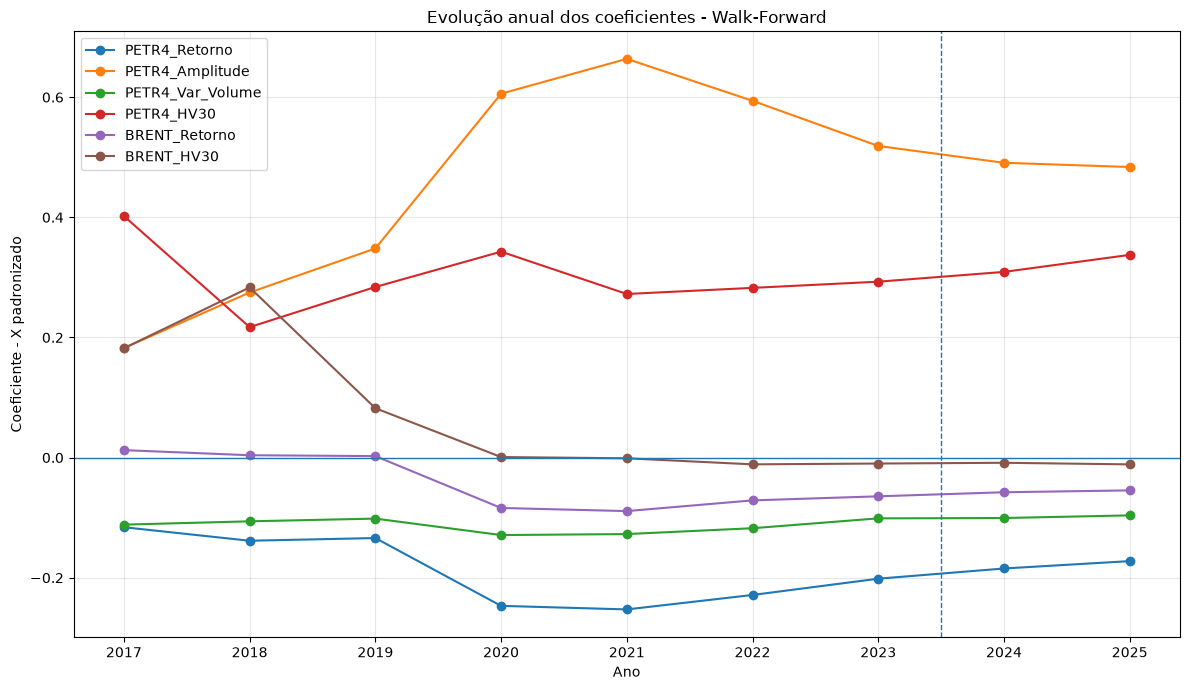

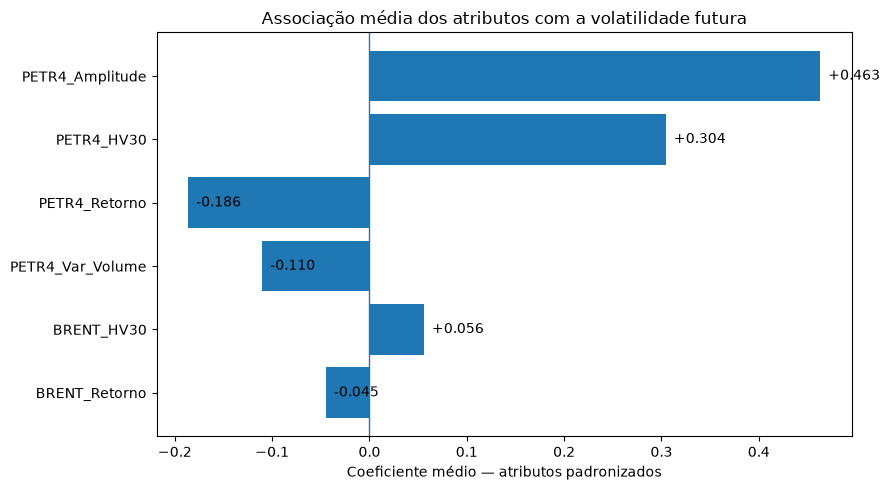

In [17]:
# =========================================================
# PASSO 14 - EXTRAÇÃO DE CONHECIMENTO
# COEFICIENTES AO LONGO DO WALK-FORWARD
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


# =========================================================
# 1. DATAS JÁ AVALIADAS NO EXPERIMENTO
# =========================================================

datas_analise = (
    resultados_completos["Date"]
    .sort_values()
    .reset_index(drop=True)
)


# =========================================================
# 2. ARMAZENAMENTO DOS COEFICIENTES
# =========================================================

coeficientes_wf = []


# =========================================================
# 3. REEXECUÇÃO DO WALK-FORWARD
#    SOMENTE PARA EXTRAÇÃO DOS COEFICIENTES
# =========================================================

for data_previsao in datas_analise:

    # -----------------------------------------------------
    # Dados disponíveis naquela data
    # -----------------------------------------------------

    dados_treino_coef = (
        base_wf[
            (base_wf["Date"] < data_previsao)
            &
            (
                base_wf["PETR4_Alvo_Fim"]
                < data_previsao
            )
        ]
        .copy()
    )


    # -----------------------------------------------------
    # Treino
    # -----------------------------------------------------

    X_treino_coef = (
        dados_treino_coef[
            atributos_petr4_brent
        ]
        .copy()
    )

    y_treino_coef = (
        dados_treino_coef[alvo]
        .copy()
    )


    # -----------------------------------------------------
    # Pipeline
    # -----------------------------------------------------

    pipeline_coef = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "modelo",
            LinearRegression()
        )
    ])


    pipeline_coef.fit(
        X_treino_coef,
        y_treino_coef
    )


    # -----------------------------------------------------
    # Recupera os coeficientes da regressão
    # -----------------------------------------------------

    modelo_coef = (
        pipeline_coef
        .named_steps["modelo"]
    )

    coeficientes = (
        modelo_coef.coef_
    )


    # -----------------------------------------------------
    # Armazena uma linha por data
    # -----------------------------------------------------

    registro = {
        "Date": data_previsao,
        "Ano": int(data_previsao.year),
        "Intercepto": float(modelo_coef.intercept_)
    }


    for atributo, coeficiente in zip(
        atributos_petr4_brent,
        coeficientes
    ):

        registro[atributo] = float(
            coeficiente
        )


    coeficientes_wf.append(
        registro
    )


# =========================================================
# 4. DATAFRAME DOS COEFICIENTES
# =========================================================

coeficientes_wf = pd.DataFrame(
    coeficientes_wf
)


print("COEFICIENTES WALK-FORWARD")
print("=" * 75)

print(
    f"Datas analisadas: "
    f"{len(coeficientes_wf)}"
)

print(
    f"Período: "
    f"{coeficientes_wf['Date'].min().date()} "
    f"a "
    f"{coeficientes_wf['Date'].max().date()}"
)


# =========================================================
# 5. RESUMO DOS COEFICIENTES
# =========================================================

resumo_coeficientes = []


for atributo in atributos_petr4_brent:

    serie = (
        coeficientes_wf[atributo]
        .astype(float)
    )


    resumo_coeficientes.append({

        "Atributo":
            atributo,

        "Coeficiente_Medio":
            float(serie.mean()),

        "Mediana":
            float(serie.median()),

        "Magnitude_Media":
            float(serie.abs().mean()),

        "Minimo":
            float(serie.min()),

        "Maximo":
            float(serie.max()),

        "Pct_Positivo":
            float(
                (serie > 0).mean() * 100
            ),

        "Pct_Negativo":
            float(
                (serie < 0).mean() * 100
            )
    })


resumo_coeficientes = pd.DataFrame(
    resumo_coeficientes
)


resumo_coeficientes = (
    resumo_coeficientes
    .sort_values(
        "Magnitude_Media",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nRESUMO DOS COEFICIENTES")
print("=" * 75)

display(
    resumo_coeficientes.round(4)
)


# =========================================================
# 6. COEFICIENTES MÉDIOS POR ANO
# =========================================================

coeficientes_anuais = (
    coeficientes_wf
    .groupby("Ano")[
        atributos_petr4_brent
    ]
    .mean()
)


print("\nCOEFICIENTES MÉDIOS POR ANO")
print("=" * 75)

display(
    coeficientes_anuais.round(4)
)


# =========================================================
# 7. MAGNITUDE MÉDIA POR ANO
# =========================================================

magnitudes_anuais = (
    coeficientes_wf
    .assign(
        **{
            atributo:
                coeficientes_wf[
                    atributo
                ].abs()

            for atributo
            in atributos_petr4_brent
        }
    )
    .groupby("Ano")[
        atributos_petr4_brent
    ]
    .mean()
)


print("\nMAGNITUDE MÉDIA DOS COEFICIENTES POR ANO")
print("=" * 75)

display(
    magnitudes_anuais.round(4)
)


# =========================================================
# 8. GRÁFICO - COEFICIENTES MÉDIOS POR ANO
# =========================================================

plt.figure(
    figsize=(12, 7)
)


for atributo in atributos_petr4_brent:

    plt.plot(
        coeficientes_anuais.index,
        coeficientes_anuais[atributo],
        marker="o",
        label=atributo
    )


plt.axhline(
    y=0,
    linewidth=1
)


plt.axvline(
    x=2023.5,
    linestyle="--",
    linewidth=1
)


plt.title(
    "Evolução anual dos coeficientes - Walk-Forward"
)

plt.xlabel(
    "Ano"
)

plt.ylabel(
    "Coeficiente - X padronizado"
)

plt.xticks(
    coeficientes_anuais.index
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# =========================================================
# COEFICIENTES MÉDIOS ASSINADOS
# =========================================================

coef_plot = (
    resumo_coeficientes[
        [
            "Atributo",
            "Coeficiente_Medio"
        ]
    ]
    .copy()
)

coef_plot["Abs"] = (
    coef_plot["Coeficiente_Medio"]
    .abs()
)

coef_plot = (
    coef_plot
    .sort_values(
        "Abs",
        ascending=True
    )
)

plt.figure(figsize=(9, 5))

plt.barh(
    coef_plot["Atributo"],
    coef_plot["Coeficiente_Medio"]
)

plt.axvline(
    0,
    linewidth=1
)

for atributo, valor in zip(
    coef_plot["Atributo"],
    coef_plot["Coeficiente_Medio"]
):
    plt.text(
        valor,
        atributo,
        f"  {valor:+.3f}",
        va="center"
    )

plt.title(
    "Associação média dos atributos com a volatilidade futura"
)

plt.xlabel(
    "Coeficiente médio — atributos padronizados"
)

plt.tight_layout()
plt.show()

### Principais padrões encontrados

Ordem da magnitude média dos coeficientes:

1. **PETR4_Amplitude:** 0,4630;
2. **PETR4_HV30:** 0,3045;
3. **PETR4_Retorno:** 0,1863;
4. **PETR4_Var_Volume:** 0,1101;
5. **BRENT_HV30:** 0,0689;
6. **BRENT_Retorno:** 0,0529.

Principais interpretações:

- amplitude e HV30 da PETR4 apresentaram as associações positivas mais fortes e estáveis;
- retornos mais negativos da PETR4 estiveram associados a maior volatilidade posterior;
- a variação do volume apresentou coeficiente negativo, mas sua interpretação deve ser cautelosa e condicional aos demais atributos;
- as duas variáveis do Brent apresentaram menor magnitude e menor estabilidade.

### Amplitude diária da PETR4

`PETR4_Amplitude` apresentou a maior magnitude média entre todos os atributos:

- coeficiente médio: **+0,4630**;
- mediana: **+0,4869**;
- magnitude média: **0,4630**;
- mínimo: **+0,1352**;
- máximo: **+0,7055**;
- sinal positivo em **100%** das regressões.

Assim, maior amplitude diária esteve consistentemente associada a maior
volatilidade nos cinco pregões seguintes, mantendo os demais atributos
constantes.

Além de possuir a maior magnitude média, o sinal permaneceu estável em todo o
período analisado.

### Volatilidade histórica da PETR4

`PETR4_HV30` apresentou:

- coeficiente médio: **+0,3045**;
- mediana: **+0,2964**;
- magnitude média: **0,3045**;
- sinal positivo em **100%** das regressões.

Esse resultado indica persistência da volatilidade: períodos com maior
volatilidade histórica estiveram consistentemente associados a maior
volatilidade posterior.

### Retorno da PETR4

`PETR4_Retorno` apresentou:

- coeficiente médio: **-0,1863**;
- magnitude média: **0,1863**;
- sinal negativo em **100%** das regressões.

Dentro do modelo linear, retornos mais negativos estiveram associados a maior
volatilidade posterior, mantendo os demais atributos constantes.

A estabilidade do sinal mostra que essa associação não ficou restrita a um
período específico.

### Variação do volume

`PETR4_Var_Volume` apresentou:

- coeficiente médio: **-0,1101**;
- magnitude média: **0,1101**;
- sinal negativo em **100%** das regressões.

Sua magnitude foi inferior às observadas para amplitude, volatilidade histórica
e retorno da PETR4, indicando uma associação linear relativamente menor com o
alvo.

O sinal negativo deve ser interpretado com cautela.

`PETR4_Var_Volume` representa a variação logarítmica do volume em relação à
observação anterior, e não o nível absoluto de volume negociado.

Além disso, o coeficiente obtido é uma associação condicional: ele representa a
relação estimada da variação do volume com o alvo mantendo constantes os demais
atributos do modelo, incluindo retorno, amplitude diária e volatilidade
histórica.

Portanto, o sinal negativo não significa que maior volume de negociação,
de forma geral, provoque menor volatilidade.

Ele indica apenas que, dentro desta especificação linear, aumentos relativos de
volume estiveram associados a menor volatilidade observada nos cinco pregões
seguintes após o controle pelos demais atributos.

Esse resultado pode depender da especificação utilizada e deverá ser reavaliado
com outras representações do volume e outros modelos.

### Informações do Brent

Os atributos do Brent apresentaram as menores magnitudes médias:

- `BRENT_HV30`: **0,0689**;
- `BRENT_Retorno`: **0,0529**.

`BRENT_HV30` apresentou sinal positivo em aproximadamente **44,8%** dos modelos
e negativo em **55,2%**, com mediana próxima de zero (**-0,0056**).

Isso indica baixa estabilidade da associação ao longo do tempo.

`BRENT_Retorno` apresentou sinal negativo em aproximadamente **78,8%** das
regressões, mas sua magnitude permaneceu pequena em comparação aos atributos da
PETR4.

Esses resultados são coerentes com a avaliação preditiva, na qual as duas
representações do Brent utilizadas não produziram redução consistente do erro.

### Ordem das associações

Considerando a magnitude média dos coeficientes:

| Posição | Atributo | Magnitude média |
|---:|---|---:|
| 1 | PETR4_Amplitude | 0,4630 |
| 2 | PETR4_HV30 | 0,3045 |
| 3 | PETR4_Retorno | 0,1863 |
| 4 | PETR4_Var_Volume | 0,1101 |
| 5 | BRENT_HV30 | 0,0689 |
| 6 | BRENT_Retorno | 0,0529 |

Portanto, os atributos relacionados ao comportamento recente da própria PETR4
apresentaram associações lineares mais fortes e mais estáveis com o alvo do que
os atributos do Brent utilizados neste experimento.

### Estabilidade temporal

Mesmo os atributos que mantiveram o mesmo sinal apresentaram mudanças de
magnitude ao longo do tempo.

A amplitude da PETR4, por exemplo, aumentou significativamente até 2021 e depois
reduziu, permanecendo, entretanto, positiva e relevante.

A volatilidade histórica também permaneceu positiva durante todo o período,
mas sua magnitude variou.

Como o `StandardScaler` é recalculado em cada janela do Walk-Forward, um desvio
padrão pode representar valores originais diferentes em períodos distintos.

Por isso, a comparação temporal dos coeficientes deve privilegiar direção,
estabilidade e importância relativa, evitando interpretações excessivamente
precisas de pequenas diferenças entre anos.

### Conhecimento extraído

Os resultados permitem destacar três padrões principais:

1. **Amplitude e volatilidade histórica da PETR4 apresentaram as associações
   positivas mais fortes e estáveis com a volatilidade posterior.**

2. **Retornos mais negativos da PETR4 estiveram consistentemente associados a
   maior volatilidade posterior dentro do modelo linear.**

3. **As duas variáveis do Brent utilizadas apresentaram menor magnitude e menor
   estabilidade, comportamento coerente com a ausência de melhoria consistente
   nas métricas preditivas.**

Assim, na configuração estudada, os atributos relacionados à própria PETR4
apresentaram associações lineares mais fortes e mais estáveis com o alvo do
que as variáveis do Brent utilizadas.

O período de 2020 apresentou movimentos extremos no Brent, que podem influenciar modelos lineares e deverão ser objeto de análise de robustez em trabalhos futuros.

## 15. Comparação com a literatura

Referência principal: **Amirshahi & Lahmiri (2023)**.

O artigo foi utilizado como referência metodológica por também tratar o problema
de previsão de volatilidade em séries financeiras.

### Pontos em comum

- previsão de volatilidade a partir de informações históricas;
- utilização de retornos financeiros;
- construção de medidas de volatilidade por janelas temporais;
- avaliação fora da amostra;
- utilização do RMSE como métrica de desempenho;
- comparação entre diferentes conjuntos de informações utilizadas pelos modelos;
- preocupação com uma avaliação temporal que preserve a ordem das observações.

### Principais diferenças

- Amirshahi & Lahmiri analisam **27 criptomoedas**, enquanto este trabalho analisa a **PETR4**;
- o artigo prevê a volatilidade do **dia seguinte**, enquanto este trabalho considera os **5 pregões seguintes**;
- o artigo utiliza modelos da família **GARCH e Deep Learning**, enquanto este trabalho utiliza **Regressão Linear**;
- no artigo, informações produzidas a partir da própria série analisada são utilizadas como atributos adicionais;
- neste trabalho, foi avaliada a contribuição de uma **série externa**, o Brent Spot;
- neste trabalho, o baseline de persistência utiliza uma janela histórica de **30 pregões**, coerente com a configuração temporal principal do experimento.

Apesar das diferenças, os dois estudos reforçam a importância das informações
históricas do próprio ativo na previsão da volatilidade.

Neste experimento, `PETR4_Amplitude` e `PETR4_HV30` apresentaram as associações
mais fortes e estáveis com a volatilidade futura, enquanto as duas representações
utilizadas do Brent não apresentaram ganho preditivo consistente.

A comparação é conceitual e metodológica. Os valores absolutos de RMSE não são
comparados diretamente, pois os estudos utilizam ativos, horizontes e modelos
diferentes.

## 16. Conclusão

O estudo mostrou que uma regressão linear simples, quando avaliada com um
protocolo temporal rigoroso, pode apresentar menor **RMSE** que um baseline
de persistência construído com a mesma janela histórica de 30 pregões.

### Principais resultados

- **2.222 previsões Walk-Forward** entre 2017 e 2025;
- a regressão PETR4 apresentou RMSE inferior ao baseline HV30 em **8 dos 9 anos**;
- **2022** foi a única exceção;
- no período histórico, a regressão PETR4 reduziu o RMSE em aproximadamente **18,56%**;
- no teste final, essa vantagem caiu para aproximadamente **2,44%**;
- no teste final, o baseline apresentou **menor MAE e menor Bias**;
- as duas representações do Brent utilizadas não apresentaram melhoria consistente;
- `PETR4_Amplitude` e `PETR4_HV30` foram os atributos com associações mais fortes e estáveis.

### Limites da interpretação

Os resultados são descritivos para esta configuração de dados, atributos,
horizonte e modelo linear.

A vantagem observada pelo RMSE não ocorreu igualmente em todas as métricas
nem apresentou a mesma magnitude ao longo do tempo.

Os resultados também não constituem evidência geral de irrelevância do Brent
nem demonstram relações causais.

A principal contribuição do trabalho foi combinar **preparação temporal,
prevenção de leakage, baseline comparável, Walk-Forward, múltiplas métricas
e interpretabilidade** em um mesmo experimento.

## 16.1 Conclusão completa

Este trabalho investigou a previsão da volatilidade da ação PETR4 utilizando
dados históricos diários da própria ação e informações do preço spot do
petróleo Brent.

O problema foi tratado como uma tarefa de regressão em série temporal.

Para cada pregão `t`, o objetivo foi utilizar informações disponíveis até o
encerramento desse pregão para prever a volatilidade observada nos
**cinco pregões seguintes**.

Para representar o comportamento histórico da PETR4 foram utilizados:

- retorno logarítmico;
- amplitude diária;
- variação logarítmica do volume;
- volatilidade histórica de 30 pregões.

Como informações externas do Brent foram utilizados:

- retorno logarítmico;
- volatilidade histórica de 30 observações.

Como referência de comparação, foi utilizado um **baseline de persistência
HV30**, no qual a volatilidade observada nos últimos 30 pregões é utilizada
como previsão para a volatilidade dos 5 pregões seguintes.

Dessa forma, o baseline e os modelos utilizam a mesma configuração temporal
principal de **30 observações históricas → 5 pregões futuros**.

A avaliação foi realizada por meio de **Walk-Forward com janela expansiva**,
preservando a ordem temporal dos dados.

Em cada origem de previsão, somente observações cujos alvos já estavam
completamente conhecidos puderam participar do treinamento.

A padronização dos atributos também foi recalculada exclusivamente com os dados
disponíveis em cada instante, evitando vazamento de informação futura.

### Desempenho preditivo

Foram avaliadas **2.222 previsões Walk-Forward** entre 2017 e 2025.

A regressão baseada somente nos atributos da PETR4 apresentou RMSE inferior ao
baseline HV30 em **8 dos 9 anos avaliados**.

A única exceção ocorreu em **2022**.

No período histórico de 2017 a 2023:

| Modelo | RMSE | MAE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline HV30 | 1,7674 | 1,0678 | -0,2782 | 0,4194 |
| Regressão PETR4 | **1,4393** | **0,8600** | **0,1523** | 0,1253 |
| Regressão PETR4 + Brent | 1,4666 | 0,8813 | 0,1198 | **0,1026** |

A regressão PETR4 reduziu o RMSE em aproximadamente **18,56%** e o MAE em
aproximadamente **19,46%** em relação ao baseline HV30.

No período reservado de teste de 2024 a 2025:

| Modelo | RMSE | MAE | R² | Bias |
|---|---:|---:|---:|---:|
| Baseline HV30 | 0,8029 | **0,6346** | -0,5373 | **0,2949** |
| Regressão PETR4 | 0,7833 | 0,6487 | -0,4631 | 0,4079 |
| Regressão PETR4 + Brent | **0,7831** | 0,6484 | **-0,4625** | 0,4122 |

No teste final, a regressão PETR4 apresentou RMSE aproximadamente **2,44%**
inferior ao baseline HV30.

Separadamente:

- **2024:** redução de aproximadamente **0,77%**;
- **2025:** redução de aproximadamente **4,42%**.

Assim, a vantagem pelo RMSE permaneceu presente no período reservado para
teste, porém em magnitude substancialmente menor que no período histórico.

### RMSE, MAE, R² e Bias

As métricas apresentaram leituras complementares.

No período histórico, a regressão PETR4 apresentou menor RMSE e menor MAE que o
baseline HV30.

No teste final, entretanto:

- o baseline apresentou o menor **MAE: 0,6346**;
- a regressão PETR4 apresentou MAE de **0,6487**;
- PETR4 + Brent apresentou MAE de **0,6484**.

Portanto, a pequena vantagem das regressões observada pelo RMSE não foi
reproduzida pelo MAE.

Todos os modelos também apresentaram R² negativo no teste final:

- baseline HV30: **-0,5373**;
- regressão PETR4: **-0,4631**;
- regressão PETR4 + Brent: **-0,4625**.

Isso indica desempenho inferior, em erro quadrático, a uma referência
retrospectiva constante baseada na média do próprio período.

O Bias também mudou entre as fases.

No teste final:

- baseline HV30: **+0,2949 p.p.**;
- regressão PETR4: **+0,4079 p.p.**;
- regressão PETR4 + Brent: **+0,4122 p.p.**.

Assim, todos os modelos apresentaram tendência média de superestimação da
volatilidade, sendo essa tendência mais elevada nas regressões.

Esses resultados reforçam que a avaliação não deve ser baseada em uma única
métrica.

### Contribuição do Brent

Nas métricas avaliadas, a inclusão do Brent não apresentou melhoria consistente
em relação à regressão baseada somente na PETR4.

Considerando os nove anos avaliados, o Brent reduziu numericamente o RMSE da
regressão PETR4 em apenas **2 anos**:

- **2017:** aproximadamente **1,15%**;
- **2025:** aproximadamente **0,37%**.

Nos demais anos, sua inclusão aumentou o RMSE.

No período histórico agregado:

- regressão PETR4: RMSE = **1,4393**;
- regressão PETR4 + Brent: RMSE = **1,4666**.

No período final de teste:

- regressão PETR4: RMSE = **0,7833**;
- regressão PETR4 + Brent: RMSE = **0,7831**.

A diferença no teste corresponde a aproximadamente **0,02%**.

Uma diferença dessa magnitude não deve ser interpretada isoladamente como
evidência de superioridade preditiva.

Assim, neste experimento, as métricas observadas não indicaram melhoria
consistente com a inclusão das duas representações utilizadas do Brent.

Esse resultado não significa ausência de relação econômica entre Petrobras e
petróleo.

Ele indica apenas que, considerando o retorno logarítmico diário e a
volatilidade histórica de 30 observações do Brent, além das defasagens,
horizonte e modelo linear adotados, não foi observada melhoria consistente
nas métricas avaliadas.

### Conhecimento extraído dos modelos

A análise dos **2.222 ajustes Walk-Forward da regressão PETR4 + Brent**
mostrou que os atributos da própria PETR4 apresentaram associações mais fortes
e mais estáveis com o alvo.

A ordem das magnitudes médias dos coeficientes foi:

1. `PETR4_Amplitude`: **0,4630**;
2. `PETR4_HV30`: **0,3045**;
3. `PETR4_Retorno`: **0,1863**;
4. `PETR4_Var_Volume`: **0,1101**;
5. `BRENT_HV30`: **0,0689**;
6. `BRENT_Retorno`: **0,0529**.

A amplitude diária e a volatilidade histórica da PETR4 apresentaram
coeficientes positivos em **100% das regressões**.

O retorno da PETR4 apresentou coeficiente negativo em **100% dos modelos**,
indicando que retornos mais negativos estiveram associados, dentro da regressão
linear, a maior volatilidade posterior.

Os atributos do Brent apresentaram menor magnitude e menor estabilidade,
comportamento coerente com a ausência de melhoria consistente observada nas
métricas preditivas.

### Estabilidade temporal

A análise anual mostrou que o desempenho relativo dos modelos varia ao longo
do tempo.

A regressão PETR4 apresentou RMSE inferior ao baseline HV30 em **8 dos 9 anos**,
mas a magnitude dessa vantagem não foi constante.

A única exceção ocorreu em **2022**, quando o baseline HV30 apresentou menor
RMSE.

No período histórico, a redução agregada do RMSE foi de aproximadamente
**18,56%**.

No teste final, essa redução caiu para aproximadamente **2,44%**.

Portanto, embora a vantagem pelo RMSE tenha permanecido no teste, sua magnitude
foi consideravelmente menor.

Além disso, no período final o baseline apresentou menor MAE e menor Bias que
as regressões.

### Relação com a literatura

Os resultados são metodologicamente compatíveis com estudos que tratam a
volatilidade como um fenômeno temporal e utilizam informações históricas para
sua previsão.

Assim como na literatura utilizada como referência, atributos derivados do
comportamento histórico do próprio ativo apresentaram relevância para a
previsão.

No presente experimento, entretanto, a inclusão das duas representações
utilizadas do Brent não produziu melhoria consistente nas métricas avaliadas.

### Limitações

Os resultados devem ser interpretados considerando algumas limitações.

O estudo utilizou regressões lineares e, portanto, relações não lineares entre
os atributos e a volatilidade podem não ter sido representadas.

Os alvos de datas consecutivas utilizam janelas futuras sobrepostas.
Dessa forma, previsões e erros consecutivos não são estatisticamente
independentes.

Este trabalho também não aplicou testes estatísticos formais de comparação da
capacidade preditiva entre os modelos.

Assim, as diferenças de RMSE e MAE são interpretadas de maneira descritiva e
não permitem concluir, por si só, se as diferenças observadas são
estatisticamente significativas.

A disponibilidade temporal do Brent foi tratada por meio de uma defasagem
conservadora de uma observação antes da integração.

Como os calendários da PETR4 e do Brent não são idênticos, essa regra resultou
em diferentes idades da informação em dias corridos.

Portanto, a defasagem utilizada não deve ser interpretada como um lag temporal
uniforme e não constitui uma reconstrução *point-in-time* exata do instante de
publicação de cada observação do Brent.

As volatilidades históricas da PETR4 e do Brent foram calculadas sobre
30 observações válidas de cada série em seus respectivos calendários.

Assim, `PETR4_HV30` e `BRENT_HV30` utilizam o mesmo número de observações, mas
podem representar intervalos diferentes em dias corridos.

A remoção dos 10 registros da PETR4 sem negociação efetiva também faz com que,
em alguns pontos, o retorno entre duas observações válidas possa abranger mais
de um dia de calendário.

O conjunto de atributos do Brent foi mais restrito que o conjunto utilizado
para a PETR4.

Enquanto a PETR4 foi representada por retorno, amplitude diária, variação de
volume e volatilidade histórica, o Brent foi representado apenas pelo retorno
diário e pela volatilidade histórica de 30 observações.

O experimento utilizou uma única família de modelo, baseada em regressão linear,
e não incluiu controles adicionais como Ibovespa ou câmbio USD/BRL.

Consequentemente, os resultados não permitem determinar se parte das
informações associadas ao Brent está sendo capturada por fatores de mercado ou
macroeconômicos não incluídos no modelo.

Assim, as conclusões sobre o Brent estão limitadas às representações utilizadas
e não devem ser interpretadas como evidência geral de irrelevância do petróleo
para a previsão da volatilidade da PETR4.

### Conclusão geral

Os resultados mostram que a regressão linear baseada nos atributos históricos
da PETR4 apresentou menor RMSE que o baseline HV30 na maior parte dos anos
avaliados.

Entretanto, a comparação com um baseline temporalmente mais equivalente mostrou
que essa vantagem foi muito mais forte no período histórico do que no teste
final.

No período reservado, a regressão PETR4 apresentou apenas **2,44% de redução
do RMSE**, enquanto o baseline apresentou menor MAE e menor Bias.

Portanto, não se observou superioridade da regressão em todas as métricas.

Nas métricas avaliadas, a inclusão das duas representações do Brent utilizadas
neste experimento também não apresentou melhoria consistente em relação à
regressão baseada somente na PETR4.

Assim, um dos principais resultados metodológicos do estudo foi demonstrar que
a **escolha de um baseline comparável, a estrutura temporal da avaliação, a
prevenção de vazamento, a análise de múltiplas métricas e a estabilidade ao
longo do tempo** são elementos fundamentais na avaliação de modelos preditivos
aplicados a séries financeiras.

Por fim, foram avaliados apenas a PETR4 e o Brent dentro de uma configuração
específica de atributos, janelas, horizonte e modelo.

Os resultados não devem ser generalizados automaticamente para outros ativos,
períodos ou representações das variáveis.

## 17. Próximos passos

As extensões serão priorizadas de forma incremental, mantendo o princípio KISS.

### Curto prazo / continuidade em Mineração de Dados

- enriquecer a representação do Brent;
- comparar janela de treinamento expansiva e móvel;
- avaliar a sensibilidade a diferentes janelas históricas, mantendo baselines temporalmente comparáveis;
- incluir IBOV e USD/BRL;
- avaliar métricas adicionais, como QLIKE e R² fora da amostra.

### Trabalho de Aprendizado de Máquina

- estrutura HAR em múltiplos horizontes;
- lags explícitos e correlação móvel PETR4–Brent;
- Ridge, Lasso, Random Forest, Gradient Boosting, SVR e XGBoost;
- diferentes representações do alvo;
- análise por regimes;
- experimentos de ablação por grupos de atributos.

### Dissertação

- GARCH, EGARCH e modelos híbridos;
- Deep Learning;
- testes Diebold-Mariano e Clark-West;
- HAC/Newey-West;
- testes placebo;
- reconstrução *point-in-time* e análises de robustez.

A ideia é evoluir do experimento simples e interpretável para modelos mais
completos, mantendo o rigor temporal, a comparabilidade entre modelos e a
prevenção de vazamento de informação.